# Pronóstico del dengue en Colombia con modelos ARIMA y SARIMAX: serie larga 2007–2025
- **Proyecto final – Series de Tiempo** · Semillero de Machine Learning (feria científica)

## 1. Introducción y pregunta de pronóstico

### 1.1 Por qué una serie más larga

En la primera versión del proyecto (2019–2025, 366 semanas) ningún modelo superó de forma significativa al **modelo ingenuo** ("habrá los mismos casos que la última semana observada"), ni con el índice ONI de El Niño, ni con clima local. Una explicación posible era la **cantidad de datos**: en 7 años solo hay una gran epidemia completa (2024), y los modelos con variables climáticas ayudaban sobre todo en ese año.

Este cuaderno repite el análisis con **toda la serie disponible en el Portal Sivigila: 2007 a 2025 (992 semanas)**, que incluye las epidemias de 2010, 2013–2016, 2019–2020 y 2023–2024. Con más epidemias los modelos tienen de dónde aprender y las pruebas estadísticas tienen más potencia. Además, la serie supera las 520 observaciones.

### 1.2 Pregunta de pronóstico y horizonte

> **¿Cuántos casos de dengue se notificarán en Colombia en cada una de las próximas 4 semanas epidemiológicas? ¿Mejora ese pronóstico al incluir el fenómeno de El Niño y el clima local?**

- **Horizonte principal: h = 4 semanas**, porque el INS analiza la vigilancia del dengue en periodos epidemiológicos de 4 semanas.
- **Horizonte complementario: h = 12 semanas** (tres periodos epidemiológicos, cerca de 3 meses).

### 1.3 Diseño del experimento (fijado antes de ejecutar)

| | Detalle |
| :--- | :--- |
| Serie | Casos semanales de dengue en Colombia, eventos 210 + 220 + 580 del Sivigila, 2007-SE01 a 2025-SE53 |
| Modelo de referencia | **M0: ingenuo**, equivalente a un ARIMA(0,1,0) |
| Modelos candidatos | ARIMA elegido con `auto_arima`; **M1** ONI; **M2** temperatura; **M3** humedad; **M4** ONI + temperatura + humedad; **M5** M4 + precipitación |
| Años de prueba | **2016 a 2025 (10 años, 522 semanas)**. Cada año se pronostica con modelos elegidos y estimados solo con los años anteriores (mínimo 9 años de entrenamiento) |
| Rezagos | Elegidos por AICc en cada entrenamiento. Mínimo h + 1 semanas para el clima y h + 12 para el ONI, para usar solo datos ya publicados |
| Métricas | RMSE y MAE, y la prueba de Diebold-Mariano frente al ingenuo |
| **Regla de selección** | El modelo con **menor RMSE a 4 semanas en los 10 años de prueba**. Solo reemplaza al ingenuo si la diferencia es **significativa al 5 %** en la prueba de Diebold-Mariano. Si no, se conserva el ingenuo por parsimonia |
| Varianza | Si los residuos del modelo final tienen efecto ARCH: **GARCH(1,1)** sobre sus residuos. No cambia el pronóstico puntual; se evalúa por la calidad de los intervalos (cobertura e *interval score*) en los mismos 10 años |
| Producto final | Pronóstico de 2026-SE01 a 2026-SE04 con intervalos del 80 % y del 95 % |

> **Cambio frente a la primera versión:** antes la selección se hacía con un solo año de prueba (2025). Evaluar con 10 años es más robusto, porque el resultado no depende de las particularidades de un año. Los resultados de 2025 se reportan aparte para que se puedan comparar.

In [1]:
!pip install pmdarima arch

In [2]:
# Librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import os
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad: los procesos son deterministas; la semilla es solo una precaucion
np.random.seed(123)
os.makedirs("figuras", exist_ok=True)      # aqui se guardan las graficas

## 2. Datos

### 2.1 Ficha de las series

| Campo | Casos de dengue | Índice ONI | Clima local |
| :--- | :--- | :--- | :--- |
| Fuente | Sivigila, INS (microdatos, solicitados al INS) | NOAA Climate Prediction Center | NASA POWER (reanálisis MERRA-2) |
| Enlace | https://portalsivigila.ins.gov.co/Paginas/Buscador.aspx | https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/oni/v6/index.php | https://power.larc.nasa.gov/ |
| Fecha de descarga | 24 de noviembre de 2026 (2007–2018); **[COMPLETAR]** (2019–2025) | 24 de noviembre de 2026 | 24 de noviembre de 2026 |
| Variables | Eventos 210 (dengue), 220 (dengue grave) y 580 (mortalidad por dengue) | Anomalía de la temperatura del Pacífico (región Niño 3.4), media móvil de 3 meses | Temperatura a 2 m (°C), humedad relativa a 2 m (%) y precipitación (mm/día) |
| Unidades | Casos notificados por semana | °C | °C, % y mm |
| Frecuencia | Semanal (semana epidemiológica, domingo a sábado) | Mensual, interpolada a diaria | Diaria, agregada a semanal |
| Periodo | 2007-SE01 a 2025-SE53 (992 semanas) | 2005 a 2025 | 2006-01-01 a 2025-12-31 |
| Ajuste estacional | Ninguno | No aplica | Ninguno |
| Archivo | `data/dengue_semanal_2007_2025.csv` | `data/oni_cpc_v6_2005_2025.csv` | `data/clima_nasa_power_7_ciudades_2006_2025.csv` |

**Construcción de la serie de casos.** Los microdatos traen un registro por paciente. Se cuentan los casos por año y semana epidemiológica de notificación, sumando los tres eventos, como hace el boletín del INS. La semana 1 es la que contiene el 4 de enero; 2008, 2014, 2020 y 2025 tienen 53 semanas.

**Cambio de clasificación en 2010.** Hasta 2009 los códigos 210 y 220 correspondían a "dengue clásico" y "dengue hemorrágico"; desde 2010 corresponden a "dengue" y "dengue grave". Como se **suman los tres eventos**, el total de casos de dengue es comparable en todo el periodo, pero la proporción de cada evento no lo es.

**Clima local.** Promedio de siete capitales (Cali, Ibagué, Bucaramanga, Villavicencio, Cartagena, Neiva y Barranquilla), ponderado por los casos de dengue de cada departamento entre **2007 y 2015**, es decir, solo con años anteriores a todos los años de prueba.

In [3]:
def inicio_anio_epidemiologico(anio):
    # La semana epidemiologica 1 es la semana (domingo a sabado) que contiene el 4 de enero
    d = dt.date(anio, 1, 4)
    return pd.Timestamp(d - dt.timedelta(days=(d.weekday() + 1) % 7))

# Casos semanales de dengue
datos = pd.read_csv("data/dengue_semanal_2007_2025.csv", parse_dates=["fecha_inicio_semana"]).set_index("fecha_inicio_semana")
datos.index = pd.DatetimeIndex(datos.index, freq="W-SUN")
serie_completa = datos["casos"].astype(float)

# Verificacion de faltantes y continuidad
dias = datos.index.to_series().diff().dropna().dt.days
print(f"Semanas en la serie: {len(datos)} (de {datos.index[0].date()} a {datos.index[-1].date()})")
print(f"Semanas esperadas entre la primera y la última fecha: {int((datos.index[-1] - datos.index[0]).days / 7) + 1}")
print(f"Valores faltantes: {int(datos['casos'].isna().sum())} | Fechas duplicadas: {int(datos.index.duplicated().sum())} | "
      f"Semanas con cero casos: {int((datos['casos'] == 0).sum())} | Días entre semanas: mínimo {dias.min()}, máximo {dias.max()}")
print(f"¿Coincide la fecha de cada semana con el calendario epidemiológico? "
      f"{'Sí' if all(inicio_anio_epidemiologico(a) + pd.Timedelta(weeks=s - 1) == f for f, a, s in zip(datos.index, datos['ANO'], datos['SEMANA'])) else 'No'}\n")

resumen_anual = datos.groupby("ANO").agg(Semanas=("SEMANA", "size"), Dengue_210=("casos_210", "sum"), Grave_220=("casos_220", "sum"),
                                         Mortalidad_580=("casos_580", "sum"), Total=("casos", "sum"), Media_semanal=("casos", "mean"),
                                         Minimo=("casos", "min"), Maximo=("casos", "max"))
resumen_anual["CV (%)"] = datos.groupby("ANO")["casos"].std() / datos.groupby("ANO")["casos"].mean() * 100
print(resumen_anual.round(1).to_string())
print(f"\nSerie completa: media {serie_completa.mean():.1f}, mediana {serie_completa.median():.1f}, desviación estándar {serie_completa.std():.1f}, "
      f"mínimo {serie_completa.min():.0f}, máximo {serie_completa.max():.0f}, CV {serie_completa.std() / serie_completa.mean() * 100:.1f} %")

Semanas en la serie: 992 (de 2006-12-31 a 2025-12-28)
Semanas esperadas entre la primera y la última fecha: 992
Valores faltantes: 0 | Fechas duplicadas: 0 | Semanas con cero casos: 0 | Días entre semanas: mínimo 7, máximo 7
¿Coincide la fecha de cada semana con el calendario epidemiológico? Sí

      Semanas  Dengue_210  Grave_220  Mortalidad_580   Total  Media_semanal  Minimo  Maximo  CV (%)
ANO                                                                                                
2007       52       35074       6922              24   42020          808.1     427    1239    24.5
2008       53       32793       4292              20   37105          700.1     419     884    13.4
2009       52       45345       7107              49   52501         1009.6     616    1703    29.7
2010       52      147224       9753             281  157258         3024.2     735    4985    48.3
2011       52       29386       1303              43   30732          591.0     477     818    13.2
201

**Interpretación**

- **No hay datos faltantes:** la serie tiene 992 semanas, las mismas que debe haber entre la primera y la última fecha, sin valores vacíos, fechas duplicadas ni semanas con cero casos. Entre semanas consecutivas siempre hay 7 días. No se imputa nada.
- **La serie supera el mínimo de 520 observaciones.**
- **Varias epidemias, no una sola:** 2010 (157 258 casos), 2013 a 2016 (entre 96 599 y 125 737 por año), 2019 (125 111), 2023 (128 250) y 2024 (312 927, la mayor del periodo). Entre ellas hay años muy bajos, como 2017 (25 305) y 2011 (30 732).
- **Serie muy variable:** la media es 1 772.0 casos por semana y la mediana 1 413.5, con un coeficiente de variación de 80.9 %. Va de 333 casos (2018) a 9 410 (2024).
- **Cambio de clasificación:** el evento 220 pesa mucho más antes de 2010 (6 922 casos en 2007 frente a 1 303 en 2011), porque hasta 2009 era "dengue hemorrágico". Por eso se trabaja con el total de los tres eventos.
- **Atípicos:** las semanas de epidemia no se eliminan ni se corrigen. Son casos reales y son justo lo que se quiere pronosticar.

In [4]:
# ONI: de trimestral a diario (cada valor se ubica en el dia 15 del mes central y se interpola)
oni_tabla = pd.read_csv("data/oni_cpc_v6_2005_2025.csv")
mes_central = dict(zip(["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"], range(1, 13)))
oni_largo = oni_tabla.melt(id_vars="year", var_name="trimestre", value_name="ONI")
oni_largo["fecha"] = pd.to_datetime(dict(year=oni_largo["year"], month=oni_largo["trimestre"].map(mes_central), day=15))
oni_diario = oni_largo.set_index("fecha")["ONI"].sort_index().resample("D").asfreq().interpolate("linear")

def oni_rezagado(k, indice=None):
    # Para cada semana t: valor del ONI en la semana t - k
    indice = datos.index if indice is None else indice
    return pd.Series(oni_diario.reindex(indice - pd.Timedelta(weeks=k)).values, index=indice, name="ONI")

# Clima local: de diario a semanal y promedio ponderado de las 7 ciudades
clima_diario = pd.read_csv("data/clima_nasa_power_7_ciudades_2006_2025.csv", parse_dates=["fecha"])
pesos_clima = {"cali": 24.5, "ibague": 14.7, "bucaramanga": 24.0, "villavicencio": 11.7, "cartagena": 4.6, "neiva": 10.9, "barranquilla": 9.6}   # % de casos 2007-2015
pesos_clima = {c: v / sum(pesos_clima.values()) for c, v in pesos_clima.items()}
print(f"Clima diario: {clima_diario.groupby('ciudad').size().to_dict()}")
print(f"Valores faltantes (-999) en el clima: {int((clima_diario[['T2M', 'RH2M', 'PRECTOTCORR']] == -999).sum().sum())}")
clima_diario["semana"] = clima_diario["fecha"] - pd.to_timedelta((clima_diario["fecha"].dt.weekday + 1) % 7, unit="D")
semanal_ciudad = clima_diario.groupby(["ciudad", "semana"]).agg(Temperatura=("T2M", "mean"), Humedad=("RH2M", "mean"),
                                                              Precipitacion=("PRECTOTCORR", "sum"), dias=("T2M", "size"))
semanal_ciudad = semanal_ciudad[semanal_ciudad["dias"] == 7].drop(columns="dias")
clima_semanal = sum(semanal_ciudad.loc[ciudad] * peso for ciudad, peso in pesos_clima.items()).dropna()
print(f"Clima semanal ponderado: {len(clima_semanal)} semanas, de {clima_semanal.index[0].date()} a {clima_semanal.index[-1].date()}")
print(clima_semanal.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

def clima_rezagado(variable, k, indice=None):
    indice = datos.index if indice is None else indice
    return pd.Series(clima_semanal[variable].reindex(indice - pd.Timedelta(weeks=k)).values, index=indice, name=variable)

# Ventanas del ultimo experimento: entrenamiento 2007-2024 y prueba 2025
train = datos[datos["ANO"] <= 2024]
test = datos[datos["ANO"] == 2025]
serie_train = train["casos"].astype(float)
print(f"\nEntrenamiento más largo: {len(train)} semanas (2007-SE01 a 2024-SE52) | Última prueba: {len(test)} semanas (2025)")

Clima diario: {'barranquilla': 7305, 'bucaramanga': 7305, 'cali': 7305, 'cartagena': 7305, 'ibague': 7305, 'neiva': 7305, 'villavicencio': 7305}
Valores faltantes (-999) en el clima: 0
Clima semanal ponderado: 1043 semanas, de 2006-01-01 a 2025-12-21
      Temperatura  Humedad  Precipitacion
mean        20.64    80.28          28.25
std          0.73     4.45          19.05
min         18.65    61.85           0.17
max         23.66    88.79         121.86

Entrenamiento más largo: 939 semanas (2007-SE01 a 2024-SE52) | Última prueba: 53 semanas (2025)


## 3. Análisis exploratorio (EDA)

### 3.1 La serie y el fenómeno de El Niño

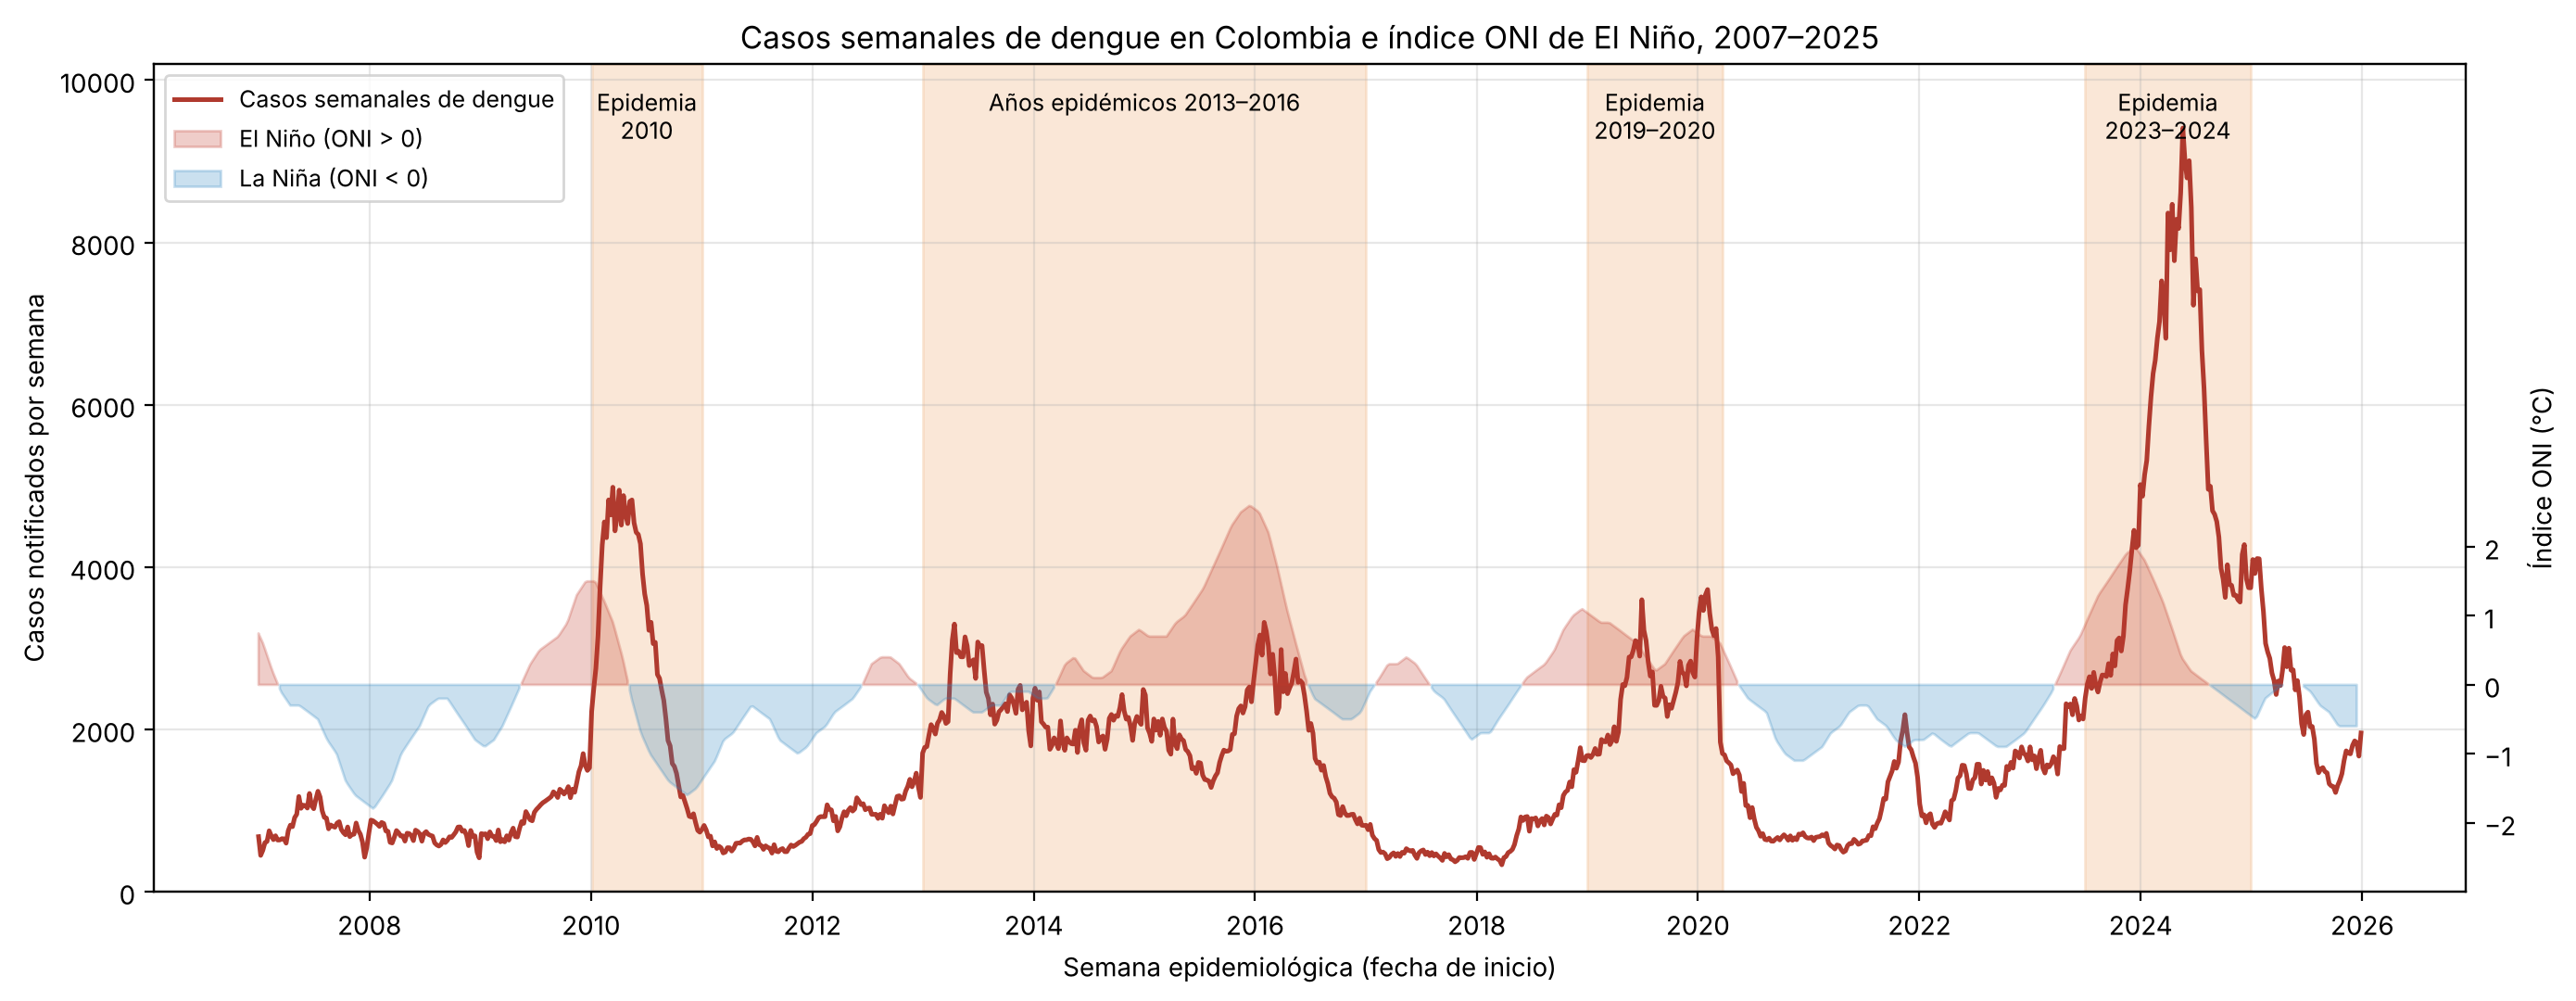

Correlación entre los casos semanales y el ONI de k semanas antes (2007–2024)
0     0.417
8     0.550
16    0.619
24    0.611
32    0.532
40    0.401


In [5]:
# Serie completa con los años epidemicos y el ONI
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(datos.index, datos["casos"], color="#B03A2E", linewidth=1.8, label="Casos semanales de dengue")
for inicio, fin, texto in [("2010-01-03", "2011-01-02", "Epidemia\n2010"), ("2013-01-01", "2016-12-31", "Años epidémicos 2013–2016"),
                           ("2019-01-01", "2020-03-22", "Epidemia\n2019–2020"), ("2023-07-01", "2024-12-29", "Epidemia\n2023–2024")]:
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fin), color="#F5CBA7", alpha=0.45)
    ax.text(pd.Timestamp(inicio) + (pd.Timestamp(fin) - pd.Timestamp(inicio)) / 2, 9900, texto, ha="center", va="top", fontsize=9)
ax.set_ylim(0, 10200)
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax2 = ax.twinx()
oni_sem = oni_rezagado(0)
ax2.fill_between(oni_sem.index, 0, oni_sem, where=oni_sem > 0, color="#C0392B", alpha=0.25, label="El Niño (ONI > 0)")
ax2.fill_between(oni_sem.index, 0, oni_sem, where=oni_sem < 0, color="#2E86C1", alpha=0.25, label="La Niña (ONI < 0)")
ax2.set_ylim(-3, 9)
ax2.set_yticks([-2, -1, 0, 1, 2])
ax2.set_ylabel("Índice ONI (°C)")
lineas = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lineas, [l.get_label() for l in lineas], loc="upper left", fontsize=9)
ax.set_title("Casos semanales de dengue en Colombia e índice ONI de El Niño, 2007–2025")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/1_serie_dengue_oni.png", dpi=200, bbox_inches="tight")
plt.show()

# Correlacion entre los casos y el ONI de k semanas antes (entrenamiento 2007-2024)
print("Correlación entre los casos semanales y el ONI de k semanas antes (2007–2024)")
print(pd.Series({k: round(serie_train.corr(oni_rezagado(k)[train.index]), 3) for k in [0, 8, 16, 24, 32, 40]}).to_string())

**Interpretación**

- **La serie está dominada por ciclos epidémicos de varios años,** no por un patrón que se repita cada año.
- **Las epidemias tienden a coincidir con El Niño o a seguirlo:** la de 2010 llega con El Niño de 2009–2010, los años altos de 2015–2016 con el de 2015–2016, la de 2019 con el de 2018–2019 y la de 2023–2024 con el de 2023–2024.
- **El efecto llega con retraso.** La correlación entre los casos y el ONI es 0.417 en la misma semana y sube hasta 0.619 con el ONI de 16 semanas antes (0.611 con 24 semanas). Es decir, el ONI de hace unos 4 a 6 meses dice más sobre los casos de hoy que el ONI de hoy.
- **Precaución:** una correlación entre dos series con tendencias no prueba causalidad. Lo que importa es si el ONI mejora el pronóstico fuera de la muestra (sección 5.2).

**Las cinco series del proyecto.** Antes de modelar se grafican juntas todas las series que entran al análisis: la variable a pronosticar (casos) y las candidatas a variables exógenas (ONI y clima local ponderado). Las líneas punteadas del ONI marcan los umbrales de El Niño (+0.5 °C) y La Niña (−0.5 °C).

      Casos de dengue  ONI (°C)  Temperatura (°C)  Humedad relativa (%)  Precipitación (mm/semana)
mean          1772.00     -0.02             20.63                 80.37                      28.62
std           1432.81      0.84              0.73                  4.46                      19.25
min            333.00     -1.79             18.65                 61.85                       0.17
max           9410.00      2.59             23.66                 88.79                     121.86


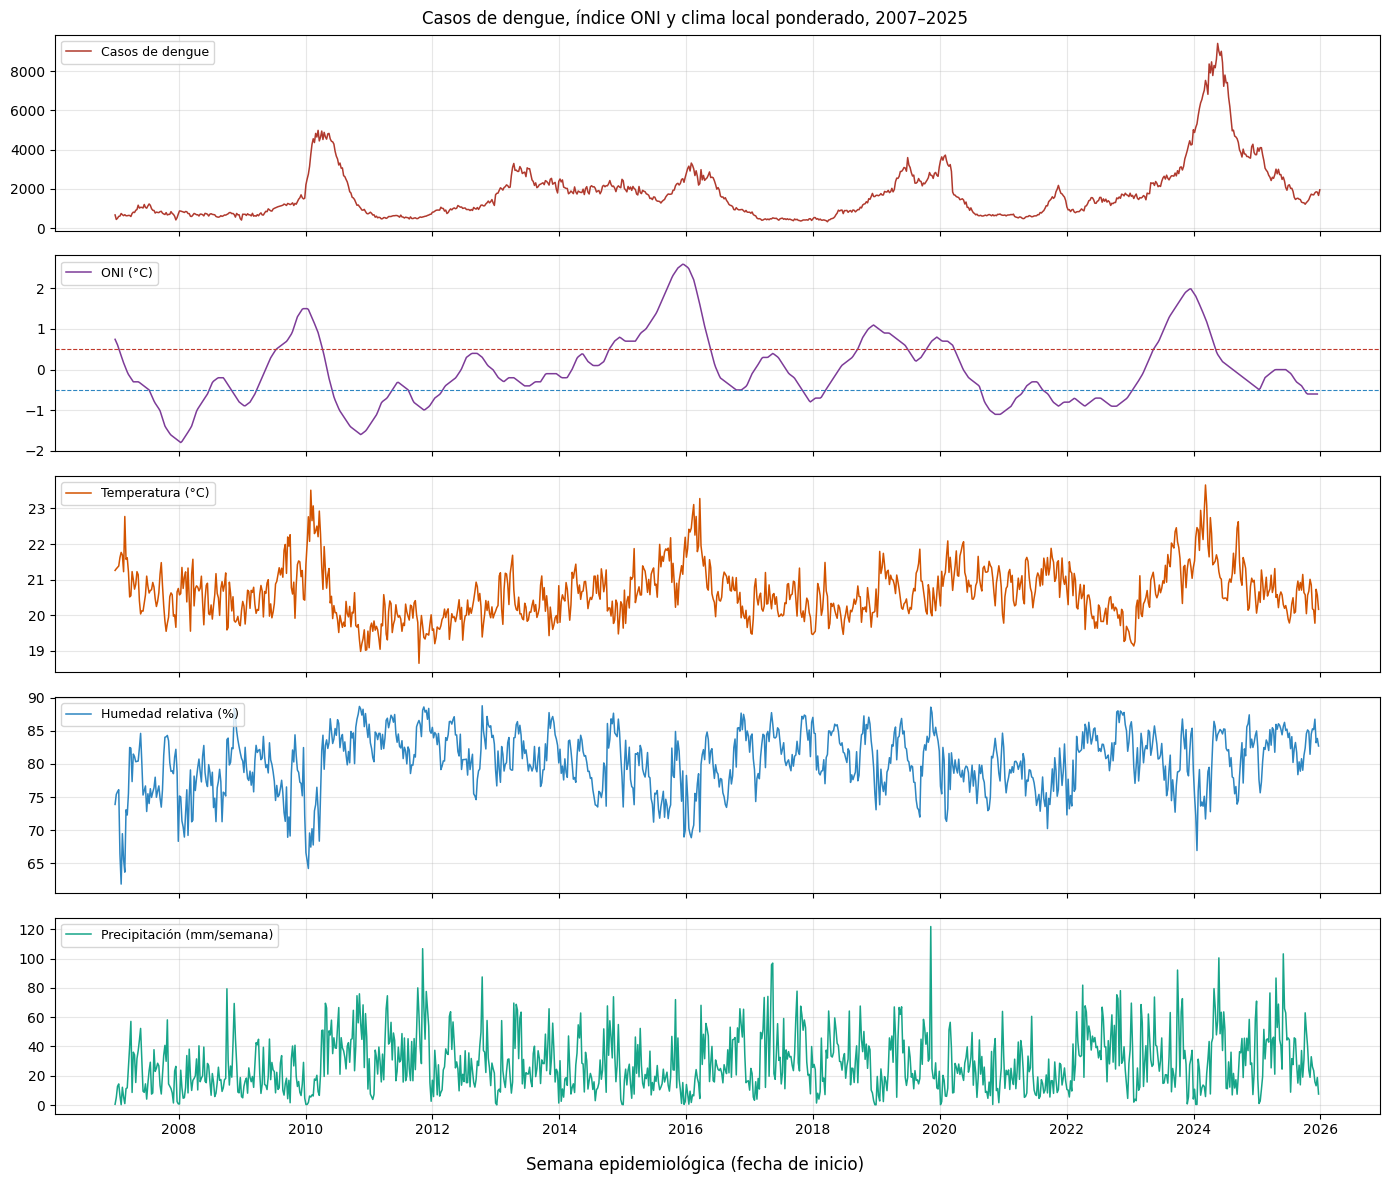

In [6]:
# Las series del proyecto: casos de dengue, ONI y clima local ponderado (2007-2025)
series_proyecto = pd.DataFrame({
    "Casos de dengue": datos["casos"].astype(float),
    "ONI (°C)": oni_rezagado(0),
    "Temperatura (°C)": clima_semanal["Temperatura"].reindex(datos.index),
    "Humedad relativa (%)": clima_semanal["Humedad"].reindex(datos.index),
    "Precipitación (mm/semana)": clima_semanal["Precipitacion"].reindex(datos.index)})
colores_series = ["#B03A2E", "#7D3C98", "#D35400", "#2E86C1", "#17A589"]

fig, axes = plt.subplots(nrows=len(series_proyecto.columns), ncols=1, sharex=True, figsize=(14, 12))
for ax, (nombre, serie), color in zip(axes, series_proyecto.items(), colores_series):
    ax.plot(serie.index, serie, color=color, linewidth=1.1, label=nombre)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(True, alpha=0.3)
axes[1].axhline(0.5, color="#C0392B", linestyle="--", linewidth=0.8)
axes[1].axhline(-0.5, color="#2E86C1", linestyle="--", linewidth=0.8)
fig.supxlabel("Semana epidemiológica (fecha de inicio)")
fig.suptitle("Casos de dengue, índice ONI y clima local ponderado, 2007–2025")
plt.tight_layout()
plt.show()
print(series_proyecto.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

**Interpretación**

- **Casos de dengue:** la serie va de 333 a 9 410 casos por semana (media 1 772, desviación estándar 1 433). Los picos de 2010, 2013–2016, 2019–2020 y 2024 son ciclos de varios años, no un patrón que se repita cada año.
- **ONI:** oscila entre −1.79 y 2.59 °C. Supera el umbral de El Niño (+0.5 °C) en 2009–2010, 2015–2016, 2018–2020 y 2023–2024, y en cada caso la subida del ONI llega **antes** que la epidemia.
- **El clima local se mueve con El Niño:**
  - La temperatura varía poco (20.6 ± 0.7 °C), pero sus picos de 2010, 2016 y 2024 coinciden con El Niño.
  - La humedad baja en esos mismos años: sus mínimos están en 2010, 2016 y 2024.
  - La precipitación es muy ruidosa y no muestra un ciclo de varios años.
- **Lectura:** como la temperatura y la humedad responden al ONI, llevan en parte la misma información. Esto anticipa lo que pasa en la sección 5.1: cuando se ponen juntas con el ONI en el modelo, dejan de ser significativas.

### 3.1.1 Descomposición STL

La descomposición STL (*Seasonal and Trend decomposition using Loess*) separa cada serie en **tendencia**, **estacionalidad** y **residuo**: $y_t = T_t + S_t + R_t$. Se usa `period=52` porque los datos son semanales y el ciclo es anual.

**Sobre `seasonal=53`.** Este parámetro es la ventana (en años) con la que se suaviza cada semana del año. Con el valor por defecto (7) el componente estacional cambia de un año a otro y termina absorbiendo las epidemias, que no son estacionales sino plurianuales. Con 53 (impar, como exige STL, y mayor que los 18 años de entrenamiento) el patrón estacional solo puede cambiar de forma suave a lo largo de los años, así las epidemias quedan en la tendencia, que es donde deben estar.

**Fuerza de la tendencia y de la estacionalidad** (Hyndman y Athanasopoulos), calculada con la función `fuerza_stl`:

$$F_T = \max\left(0,\ 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(T_t + R_t)}\right), \qquad F_S = \max\left(0,\ 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

Ambas van de 0 a 1: cerca de 1 el componente es fuerte, cerca de 0 casi no existe.

          Serie  Fuerza tendencia  Fuerza estacionalidad
Casos de dengue            0.8833                 0.1860
            ONI            0.8981                 0.0418
    Temperatura            0.6329                 0.3315
        Humedad            0.5196                 0.5302
  Precipitación            0.1818                 0.3353

Patrón estacional de los casos: máximo en la semana 22 (+384 casos), mínimo en la semana 40 (-326 casos)


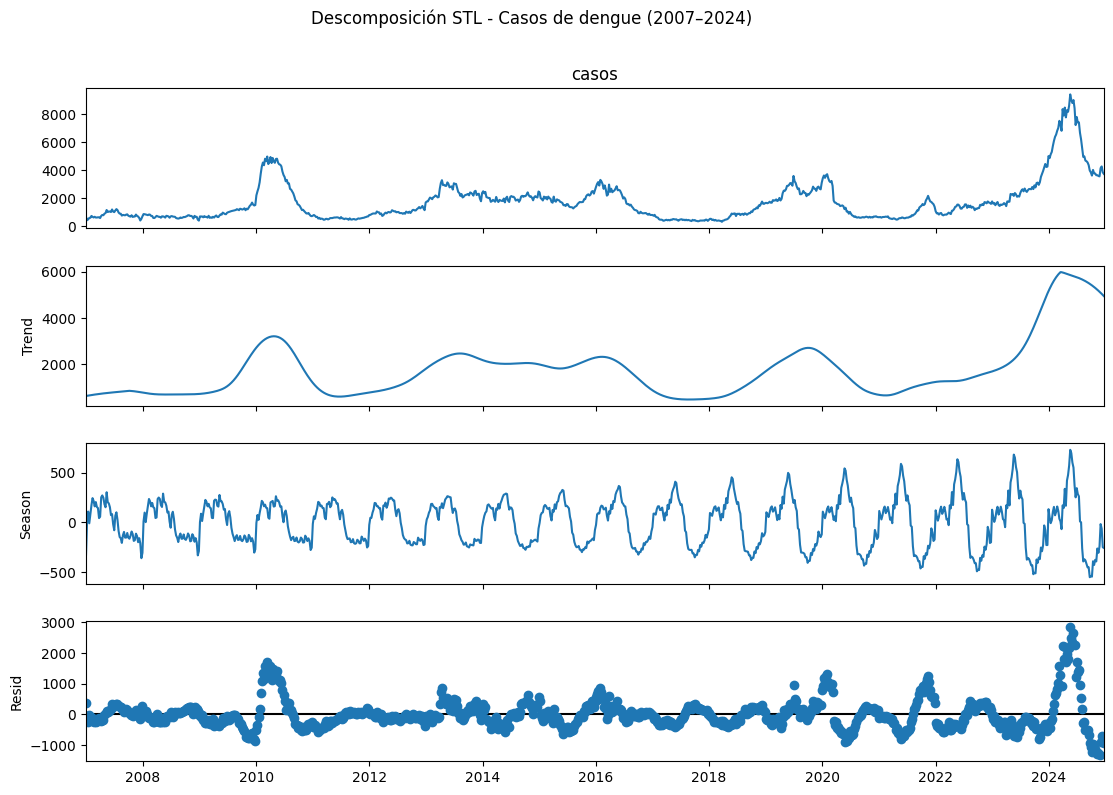

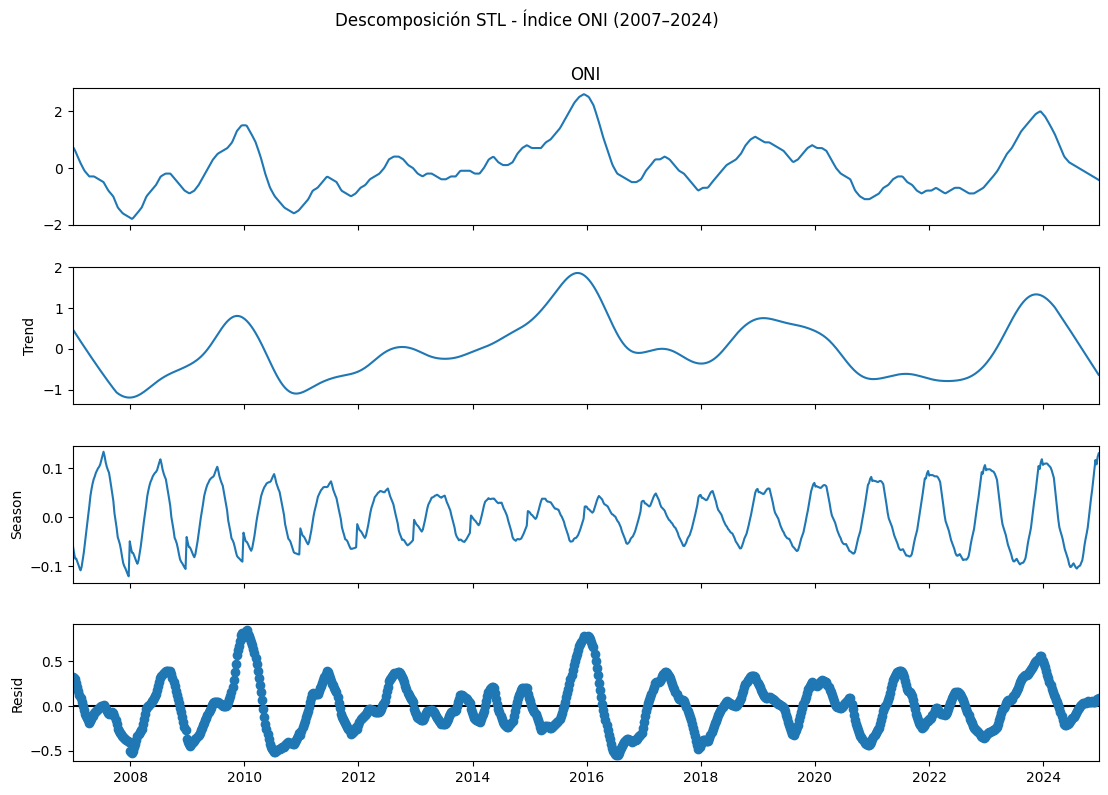

In [7]:
from statsmodels.tsa.seasonal import STL

# Fuerza de la tendencia y de la estacionalidad (Hyndman y Athanasopoulos)
def fuerza_stl(stl_fit):
    Ft = max(0, 1 - stl_fit.resid.var() / (stl_fit.trend + stl_fit.resid).var())
    Fs = max(0, 1 - stl_fit.resid.var() / (stl_fit.seasonal + stl_fit.resid).var())
    return round(Ft, 4), round(Fs, 4)

# Descomposicion STL de los casos (ciclo anual = 52 semanas), entrenamiento 2007-2024
# seasonal=53: el patron estacional cambia despacio de un año a otro; con la ventana por defecto (7)
# la "estacionalidad" absorberia las epidemias de cada año (ver la interpretacion)
stl_casos = STL(serie_train, period=52, seasonal=53).fit()
fig = stl_casos.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Descomposición STL - Casos de dengue (2007–2024)", y=1.02)
plt.show()

# Descomposicion STL del ONI (variable exogena principal)
oni_train = oni_rezagado(0)[train.index]
stl_oni = STL(oni_train, period=52, seasonal=53).fit()
fig = stl_oni.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Descomposición STL - Índice ONI (2007–2024)", y=1.02)
plt.show()

stl_clima = {v: STL(clima_semanal[v].reindex(train.index).interpolate(), period=52, seasonal=53).fit() for v in ["Temperatura", "Humedad", "Precipitacion"]}
tab_fuerza = pd.DataFrame({
    "Serie": ["Casos de dengue", "ONI", "Temperatura", "Humedad", "Precipitación"],
    "Fuerza tendencia": [fuerza_stl(stl_casos)[0], fuerza_stl(stl_oni)[0]] + [fuerza_stl(stl_clima[v])[0] for v in stl_clima],
    "Fuerza estacionalidad": [fuerza_stl(stl_casos)[1], fuerza_stl(stl_oni)[1]] + [fuerza_stl(stl_clima[v])[1] for v in stl_clima]})
print(tab_fuerza.to_string(index=False))
estacional_semana = stl_casos.seasonal.groupby(train["SEMANA"]).mean()
print(f"\nPatrón estacional de los casos: máximo en la semana {estacional_semana.idxmax()} ({estacional_semana.max():+.0f} casos), "
      f"mínimo en la semana {estacional_semana.idxmin()} ({estacional_semana.min():+.0f} casos)")

**Interpretación**

- **Casos de dengue: tendencia fuerte y estacionalidad débil** ($F_T$ = 0.883, $F_S$ = 0.186). Lo que domina la serie son los ciclos epidémicos de varios años, que STL pone en la tendencia, no un patrón anual. Coincide con la ACF de la sección 3.2, donde la autocorrelación en el rezago 52 es pequeña.
- **El patrón estacional existe, pero es moderado:**
  - Los casos suben en el primer semestre, con el máximo en la semana 22 (+384 casos sobre la tendencia), y bajan en el segundo, con el mínimo en la semana 40 (−326).
  - La amplitud crece con el nivel de la serie: el rango del componente estacional pasa de unos 480 casos en 2012 a unos 1 290 en 2024. Con `seasonal=53` ese cambio es suave, casi lineal, y no copia las epidemias de cada año.
- **El residuo de los casos es grande justo en las epidemias** (2010, 2020, 2024): las subidas y bajadas rápidas no las explica ni la tendencia ni la estacionalidad. Esto anticipa los residuos con colas pesadas y efecto ARCH de la sección 5.3.
- **ONI: casi sin estacionalidad** ($F_S$ = 0.042) **y con tendencia muy fuerte** ($F_T$ = 0.898). Su dinámica son los ciclos de El Niño y La Niña, de 2 a 7 años, no el calendario.
- **Clima local:**
  - La humedad es la más estacional ($F_S$ = 0.530).
  - La temperatura tiene tendencia moderada ($F_T$ = 0.633) y algo de estacionalidad ($F_S$ = 0.332).
  - La precipitación es sobre todo ruido ($F_T$ = 0.182, $F_S$ = 0.335).
- **Consecuencia para el modelo:** con una estacionalidad tan débil en los casos, es coherente modelar la dinámica con un ARIMA no estacional más variables exógenas, que es lo que hacen los modelos M1 a M5.

### 3.1.2 Casos frente al ONI rezagado

Se grafica la dispersión entre la variable a pronosticar y la exógena con distintos rezagos, con la correlación de Pearson, su p-valor (H₀: correlación igual a 0) y una curva **Lowess** (regresión local, `frac=0.3`) que muestra la forma de la relación sin suponer que es lineal. El asterisco marca correlaciones significativas al 5 %.

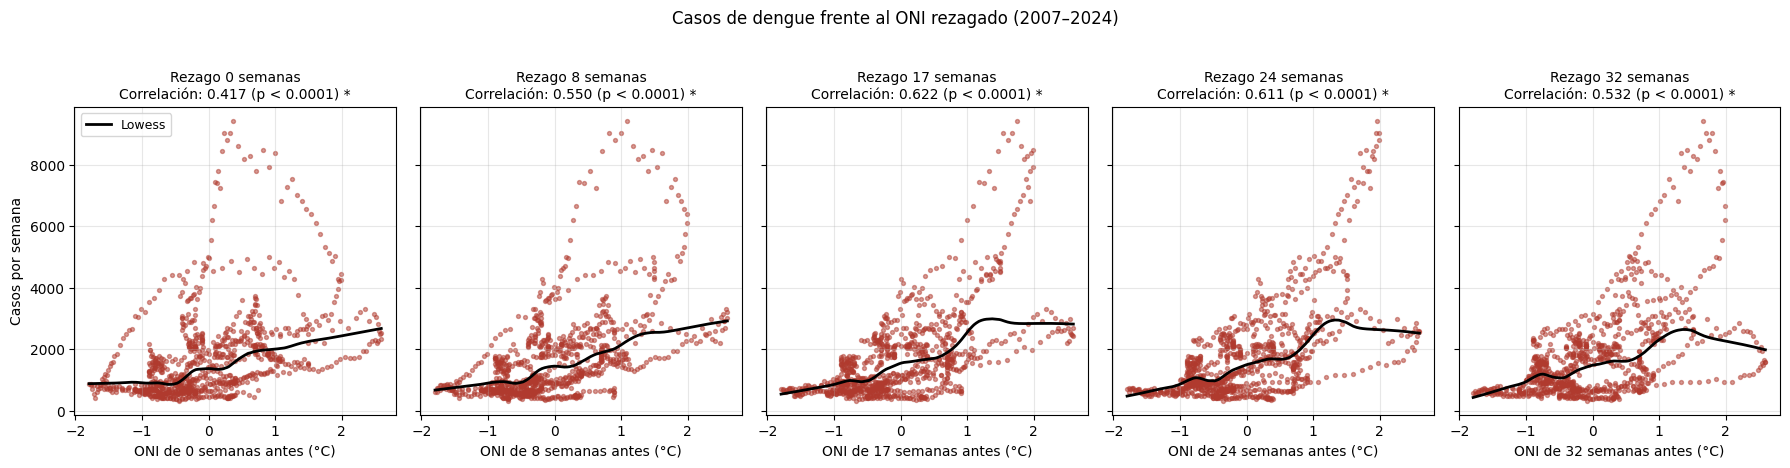

In [8]:
from scipy.stats import pearsonr
from statsmodels.nonparametric.smoothers_lowess import lowess

# Casos frente al ONI de k semanas antes (entrenamiento 2007-2024)
rezagos_oni = [0, 8, 17, 24, 32]
fig, axes = plt.subplots(nrows=1, ncols=len(rezagos_oni), sharey=True, figsize=(18, 4.5))
for ax, k in zip(axes, rezagos_oni):
    x = oni_rezagado(k)[train.index]
    ok = x.notna()
    r, p_valor = pearsonr(x[ok], serie_train[ok])
    ax.scatter(x[ok], serie_train[ok], s=8, alpha=0.5, color="#B03A2E")
    suave = lowess(serie_train[ok], x[ok], frac=0.3)
    ax.plot(suave[:, 0], suave[:, 1], color="black", linewidth=2, label="Lowess")
    ax.set_title(f"Rezago {k} semanas\nCorrelación: {r:.3f} ({'p < 0.0001' if p_valor < 0.0001 else f'p = {p_valor:.4f}'}){' *' if p_valor < 0.05 else ''}", fontsize=10)
    ax.set_xlabel(f"ONI de {k} semanas antes (°C)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Casos por semana")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Casos de dengue frente al ONI rezagado (2007–2024)", y=1.03)
plt.tight_layout()
plt.show()

**Interpretación**

- **La correlación sube con el rezago y luego baja:** 0.417 en la misma semana, 0.550 con 8 semanas, **0.622 con 17 semanas**, 0.611 con 24 y 0.532 con 32. El máximo está cerca de las 17 semanas, el mismo rezago que eligió el AICc para el ONI en la sección 5.1. Todas son significativas (p < 0.0001).
- **La relación no es lineal (curva Lowess, rezago 17):**
  - Con el ONI por debajo de −0.5 °C (La Niña) los casos se quedan bajos, entre 700 y 1 000 por semana.
  - Entre 0 y 1.3 °C suben con fuerza.
  - Por encima de 1.3 °C la curva se aplana cerca de 3 000 casos.
- **El ONI dice cuándo sube el riesgo, no qué tan grande será la epidemia.** Con un ONI parecido (entre 1.5 y 2.6 °C, 17 semanas antes), 2016 quedó cerca de 3 000 casos por semana y 2024 pasó de 9 000.
- **Precaución con los p-valores:** los puntos son semanas consecutivas, así que no son observaciones independientes. Por eso aparecen como "trayectorias" en la nube, y los p-valores de Pearson exageran la significancia. Lo que valida al ONI es la evaluación fuera de la muestra (sección 5.2), no esta correlación.

### 3.2 Estacionariedad, ACF y PACF (entrenamiento 2007–2024)

**Serie en niveles.** Primero se mira la serie sin transformar. Las pruebas que se usan en esta sección tienen hipótesis opuestas, por eso se aplican las dos:

- **ADF (Dickey-Fuller aumentada):** H₀: la serie tiene raíz unitaria (no es estacionaria). Si p < 0.05 se rechaza y la serie es estacionaria.
- **KPSS:** H₀: la serie es estacionaria. Si p < 0.05 se rechaza y la serie no es estacionaria.

En la **ACF** una serie no estacionaria se reconoce porque la autocorrelación baja muy despacio; en la **PACF** se mira en qué rezago se corta la autocorrelación parcial. Las bandas azules son el intervalo de 95 % ($\pm 1.96/\sqrt{n}$).

ACF en niveles: rezago 1 = 0.991, 13 = 0.784, 26 = 0.475, 52 = 0.049, 104 = -0.160
PACF en niveles: rezago 1 = 0.992, rezago 2 = 0.027 | Banda ±0.064


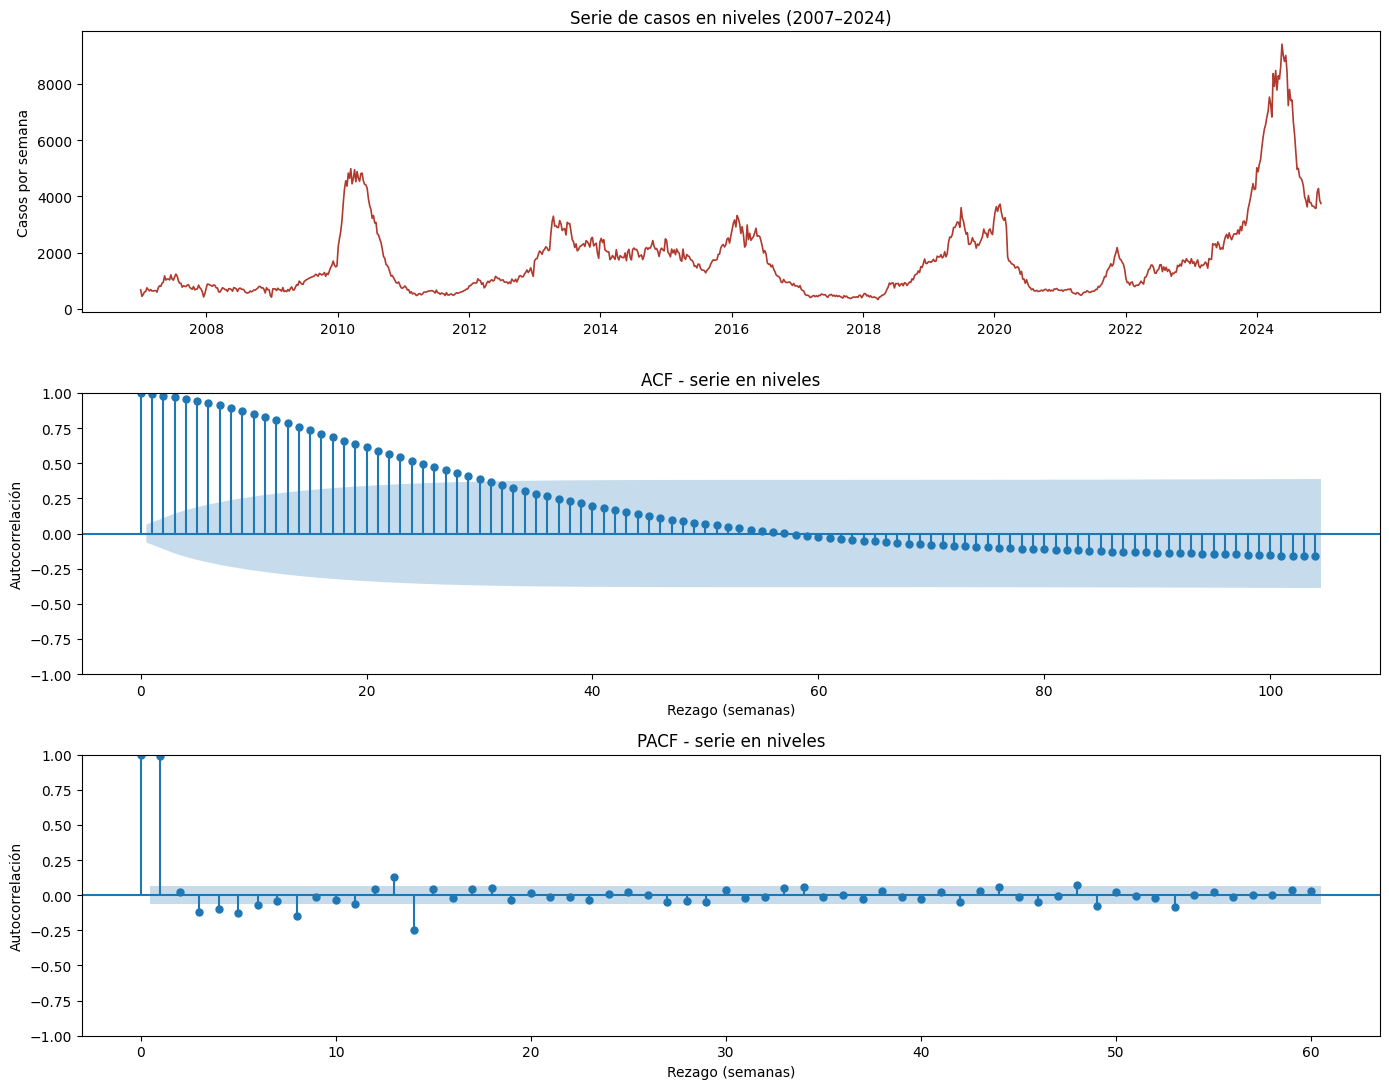

In [9]:
# Serie en niveles: grafico, ACF y PACF (entrenamiento 2007-2024)
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
axes[0].plot(serie_train.index, serie_train, color="#B03A2E", linewidth=1.2)
axes[0].set_title("Serie de casos en niveles (2007–2024)")
axes[0].set_ylabel("Casos por semana")
plot_acf(serie_train, lags=104, ax=axes[1], title="ACF - serie en niveles")
plot_pacf(serie_train, lags=60, ax=axes[2], title="PACF - serie en niveles")
for ax in axes[1:]:
    ax.set_xlabel("Rezago (semanas)")
    ax.set_ylabel("Autocorrelación")
plt.tight_layout()
plt.show()
from statsmodels.tsa.stattools import acf as acf_valores, pacf as pacf_valores
acf_niv = acf_valores(serie_train, nlags=104)
print(f"ACF en niveles: rezago 1 = {acf_niv[1]:.3f}, 13 = {acf_niv[13]:.3f}, 26 = {acf_niv[26]:.3f}, 52 = {acf_niv[52]:.3f}, 104 = {acf_niv[104]:.3f}")
print(f"PACF en niveles: rezago 1 = {pacf_valores(serie_train, nlags=5)[1]:.3f}, rezago 2 = {pacf_valores(serie_train, nlags=5)[2]:.3f} | Banda ±{1.96 / np.sqrt(len(serie_train)):.3f}")

**Interpretación**

- **La serie no oscila alrededor de una media fija:** pasa largos periodos en niveles bajos y sube en epidemias que duran meses.
- **La ACF baja muy despacio:**
  - Vale 0.991 en el rezago 1, 0.784 en el 13 y 0.475 en el 26, y solo entra en la banda de confianza cerca del rezago 33.
  - Ese decaimiento lento es la señal típica de una serie **no estacionaria** o muy persistente: lo que pasa esta semana depende mucho de lo que pasó varios meses atrás.
- **La PACF tiene un solo pico grande, en el rezago 1 (0.992),** y en el rezago 2 cae a 0.027, dentro de la banda de ±0.064.
  - Ese patrón indica que la serie se comporta casi como una caminata aleatoria, $y_t \approx y_{t-1} + \varepsilon_t$.
  - Los picos pequeños que aparecen después (rezagos 3 a 5, 8, 13 y 14) se estudian mejor en la serie diferenciada.
- **Conclusión gráfica:** la serie en niveles necesita una diferencia (d = 1) antes de identificar los términos AR y MA. Las pruebas formales de la siguiente celda lo confirman.

**Pruebas formales y serie diferenciada.** La siguiente celda aplica ADF y KPSS a la serie en niveles y a la serie con una diferencia ($\Delta y_t = y_t - y_{t-1}$), y grafica la serie diferenciada con su ACF y su PACF.

SERIE EN NIVELES
PRUEBA DE ESTACIONARIEDAD
                                   Test  Estadístico  P-valor Estacionario
0  Prueba Augmented Dickey-Fuller (ADF)      -2.9839   0.0364           Sí
1                           Prueba KPSS       0.7335   0.0105           No

SERIE CON UNA DIFERENCIA
PRUEBA DE ESTACIONARIEDAD
                                   Test  Estadístico  P-valor Estacionario
0  Prueba Augmented Dickey-Fuller (ADF)      -7.0187      0.0           Sí
1                           Prueba KPSS       0.0338      0.1           Sí


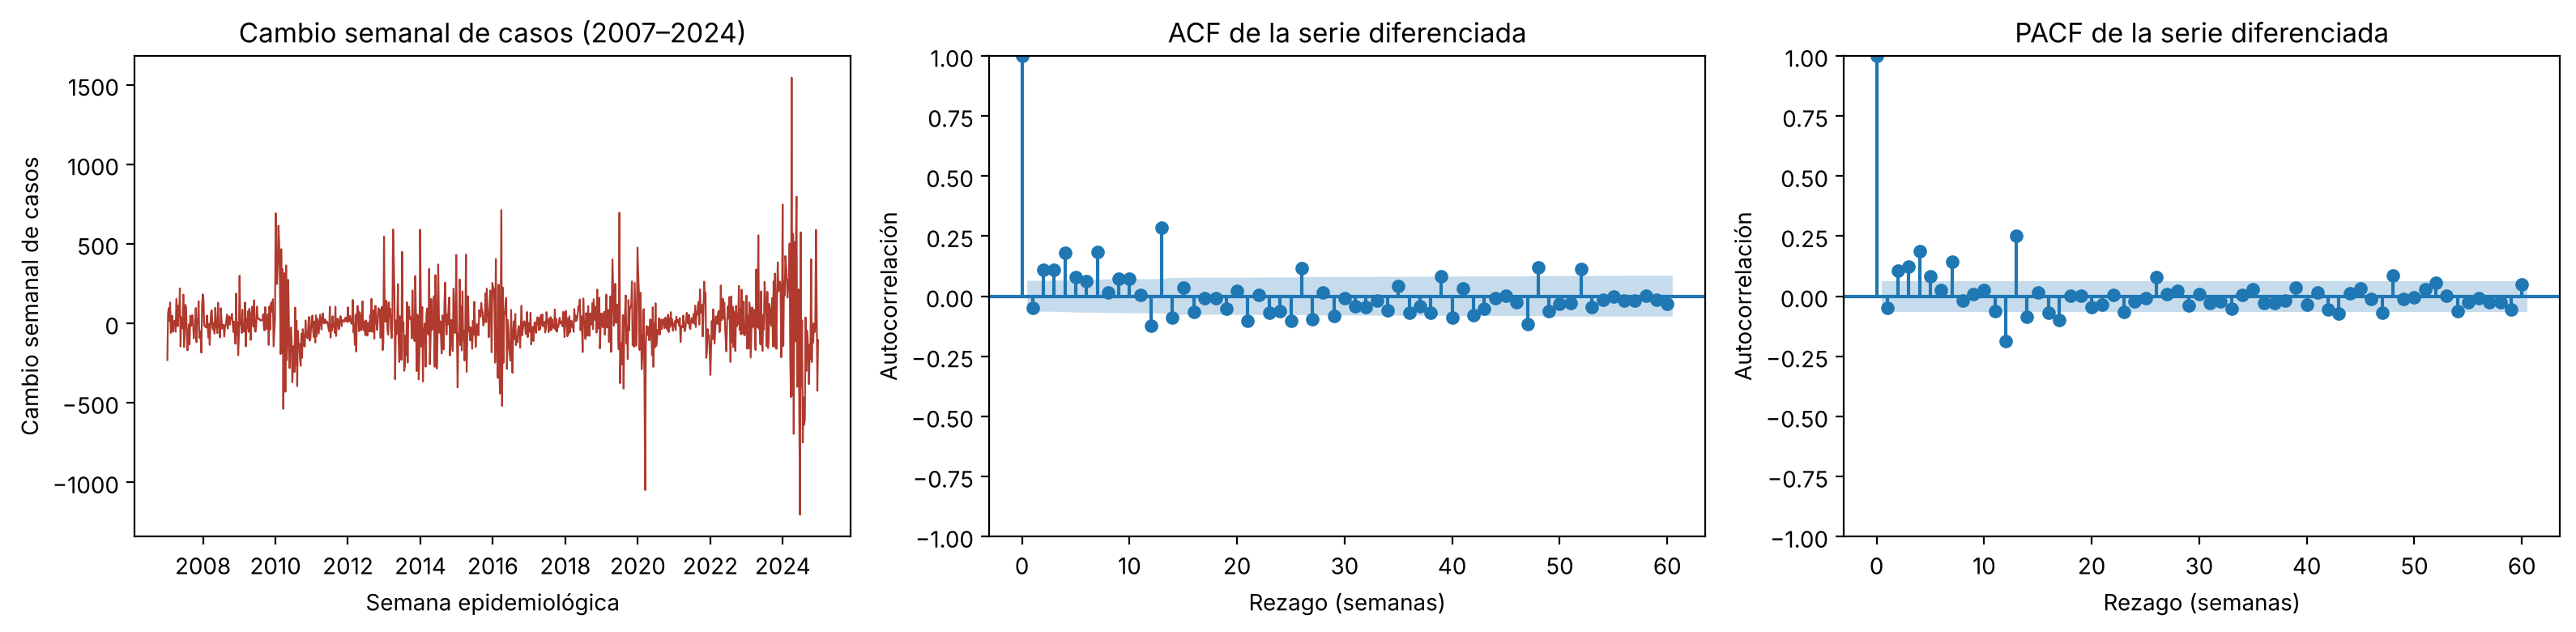

Autocorrelación de la serie diferenciada: {1: -0.048, 2: 0.109, 3: 0.112, 4: 0.184, 52: 0.146} | Banda ±0.064


In [10]:
def test_estacionariedad(datos):
    # Augmented Dickey-Fuller
    adf_result = adfuller(datos)
    # KPSS
    kpss_result = kpss(datos, regression='c')

    # Tabla de resultados
    tab_test = pd.DataFrame({
        'Test'        : ["Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"],
        'Estadístico' : [round(adf_result[0],  4), round(kpss_result[0],  4)],
        'P-valor'     : [round(adf_result[1], 4), round(kpss_result[1], 4)],
        "Estacionario" : ["Sí" if adf_result[1] < 0.05 else "No", "No" if kpss_result[1] < 0.05 else "Sí"]
    })

    print("=" * 80)
    print("PRUEBA DE ESTACIONARIEDAD")
    print("=" * 80)
    print(tab_test)
    print("=" * 80)

print("SERIE EN NIVELES")
test_estacionariedad(serie_train)
diff_serie_train = serie_train.diff().dropna()
print("\nSERIE CON UNA DIFERENCIA")
test_estacionariedad(diff_serie_train)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(diff_serie_train, color="#B03A2E", linewidth=0.8)
axes[0].set_title("Cambio semanal de casos (2007–2024)")
axes[0].set_xlabel("Semana epidemiológica")
axes[0].set_ylabel("Cambio semanal de casos")
plot_acf(diff_serie_train, lags=60, ax=axes[1], title="ACF de la serie diferenciada")
plot_pacf(diff_serie_train, lags=60, ax=axes[2], title="PACF de la serie diferenciada")
for ax in axes[1:]:
    ax.set_xlabel("Rezago (semanas)")
    ax.set_ylabel("Autocorrelación")
plt.tight_layout()
plt.show()
valores_acf = pd.Series({k: round(diff_serie_train.autocorr(k), 3) for k in [1, 2, 3, 4, 52]})
print(f"Autocorrelación de la serie diferenciada: {valores_acf.to_dict()} | Banda ±{1.96 / np.sqrt(len(diff_serie_train)):.3f}")

**Interpretación**

- **En niveles las pruebas no coinciden:** ADF rechaza la raíz unitaria (p = 0.0364), pero KPSS rechaza la estacionariedad (p = 0.0105). Con una serie más larga los casos tienden a volver a un nivel medio después de cada epidemia, pero muy despacio.
- **Con una diferencia las dos pruebas coinciden:** la serie es estacionaria (ADF p < 0.001, KPSS p = 0.10). Se trabaja con **d = 1**, aunque `auto_arima` puede elegir d = 0 en algunos entrenamientos.
- **ACF de la serie diferenciada:** hay autocorrelación positiva en los rezagos 2, 3 y 4 (0.109, 0.112 y 0.184, fuera de la banda de ±0.064), lo que justifica términos AR y MA. En el rezago 52 hay una autocorrelación pequeña (0.146): la estacionalidad anual existe, pero es débil.

## 4. Método empírico

**Modelos.** Todos se estiman con la clase `ARIMA` de statsmodels.

- **M0, ingenuo:** $\hat{y}_{t+h} = y_t$. Equivale a un ARIMA(0,1,0).
- **ARIMA:** orden elegido con `auto_arima` (menor AICc), sin variables exógenas.
- **M1 a M5, SARIMAX:** $Casos_t = \beta' X_{t-k} + \eta_t$, con $\eta_t \sim ARIMA(p,d,q)$ y $X$ el ONI y/o las variables de clima local rezagadas.

**Rezagos sin usar información del futuro.** El pronóstico de la semana $t$ se hace en la semana $t - h$. Para el clima local se supone una semana de retraso de publicación, así que el rezago mínimo es $k = h + 1$; se prueban 12 candidatos ($h + 1$ a $h + 12$). El ONI de un trimestre se publica unas 12 semanas después de su punto medio, así que su rezago mínimo es $k = h + 12$; se prueban hasta $h + 30$. En cada entrenamiento se escoge, para cada variable, el rezago con menor AICc en un ARIMA(0,1,0) + la variable.

**Evaluación con origen móvil.** Para cada año de prueba (2016 a 2025):
1. Se toman como entrenamiento todos los años anteriores.
2. Con ese entrenamiento se eligen los rezagos y los órdenes y se estiman los modelos.
3. Cada semana del año de prueba se pronostica $h$ semanas antes, con los casos observados hasta ese momento. Los parámetros no se reestiman dentro del año.

**Prueba de Diebold-Mariano.** Compara los errores de dos modelos semana a semana. H0: los dos pronostican igual de bien. Se usa la corrección de Harvey, Leybourne y Newbold y se aplica con pérdida cuadrática (la del RMSE) y absoluta (la del MAE). DM < 0 indica que el modelo se equivoca menos que el ingenuo.

**Modelo de varianza GARCH(1,1).** Los modelos anteriores suponen que la varianza del error es constante. Si los residuos del modelo final tienen efecto ARCH, se modela su varianza condicional con un GARCH(1,1), estimado en dos etapas (primero el SARIMAX y después el GARCH sobre sus residuos $\varepsilon_t$):

$$\varepsilon_t = \sigma_t z_t, \qquad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

El GARCH **no cambia el pronóstico puntual**, solo el ancho de los intervalos. La varianza del error a $h$ semanas se obtiene con los pesos $\psi_j$ del ARIMA: $\operatorname{Var}(e_{t+h}) = \sum_{j=0}^{h-1} \psi_j^2\,\sigma_{t+h-j}^2$. Si $\alpha + \beta < 1$, la volatilidad vuelve a un nivel fijo; si $\alpha + \beta = 1$ (IGARCH), no vuelve.

**Calidad de los intervalos.** Se mide con la cobertura real (porcentaje de semanas en que el dato observado cae dentro del intervalo), el ancho medio y el *interval score* de Gneiting y Raftery (2007), que suma el ancho y una penalización cuando el dato queda por fuera. Menor es mejor:

$$IS_\gamma = (L_s - L_i) + \frac{2}{\gamma}(L_i - y)\,\mathbb{1}(y < L_i) + \frac{2}{\gamma}(y - L_s)\,\mathbb{1}(y > L_s)$$

donde $L_i$ y $L_s$ son los límites del intervalo, $y$ el dato observado y $\gamma$ = 0.05 para el intervalo del 95 % y 0.20 para el del 80 %. Los *interval score* de los dos métodos se comparan con la misma prueba de Diebold-Mariano.

In [11]:
def pronostico_h_semanas(modelo, h, semanas_objetivo, exog=None):
    pronosticos_h = []
    for semana in semanas_objetivo:
        n_obs = serie_completa.index.get_loc(semana) - h + 1   # semanas observadas al momento de pronosticar
        if exog is None:
            res = modelo.apply(serie_completa.iloc[:n_obs])
            f = res.get_forecast(steps=h)
        else:
            res = modelo.apply(serie_completa.iloc[:n_obs], exog=exog.iloc[:n_obs])
            f = res.get_forecast(steps=h, exog=exog.iloc[n_obs:n_obs + h])
        pronosticos_h.append(f.predicted_mean.iloc[-1])
    return np.array(pronosticos_h)

def prueba_diebold_mariano(e1, e2, h=1, potencia=2):
    e1, e2 = np.asarray(e1, dtype=float), np.asarray(e2, dtype=float)
    d = np.abs(e1)**potencia - np.abs(e2)**potencia          # diferencia de perdidas
    n = len(d)
    d_media = d.mean()
    # Varianza de largo plazo de la media de d: autocovarianzas hasta el rezago h - 1
    gamma = [np.sum((d[k:] - d_media) * (d[:n - k] - d_media)) / n for k in range(h)]
    var_d_media = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var_d_media <= 0:                                       # si la suma da negativa se usa solo la varianza
        var_d_media = gamma[0] / n
    dm = d_media / np.sqrt(var_d_media)
    correccion = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)   # Harvey, Leybourne y Newbold
    dm_hln = dm * correccion
    p_valor = 2 * (1 - stats.t.cdf(abs(dm_hln), df=n - 1))
    return dm_hln, p_valor

def diagnostico_residuos(modelos: dict, rezagos=[13, 26, 52], rezagos_arch=13) -> pd.DataFrame:
    filas = []
    for nombre, m in modelos.items():
        res = m.resid[1:]
        lb = acorr_ljungbox(res, lags=rezagos, return_df=True)
        jb_est, jb_p = stats.jarque_bera(res)
        sw_est, sw_p = stats.shapiro(res)
        arch_est, arch_p, _, _ = het_arch(res, nlags=rezagos_arch)
        fila = {"Modelo": nombre}
        for k in rezagos:
            fila[f"Ljung-Box p (rezago {k})"] = lb.loc[k, "lb_pvalue"]
        fila["Ruido blanco"] = "Sí" if (lb["lb_pvalue"] >= 0.05).all() else "No"
        fila["Jarque-Bera (estadístico)"] = jb_est
        fila["Jarque-Bera p"] = jb_p
        fila["Shapiro-Wilk (estadístico)"] = sw_est
        fila["Shapiro-Wilk p"] = sw_p
        fila["Residuos normales"] = "Sí" if (jb_p >= 0.05 and sw_p >= 0.05) else "No"
        fila[f"ARCH-LM (estadístico, {rezagos_arch} rezagos)"] = arch_est
        fila["ARCH-LM p"] = arch_p
        fila["Efecto ARCH"] = "Sí" if arch_p < 0.05 else "No"
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Modelo")

def elegir_rezago(y_tr, funcion_rezago, rezagos):
    # Rezago con menor AICc en un ARIMA(0,1,0) + la variable, solo con el entrenamiento recibido
    aicc = {k: ARIMA(y_tr, exog=funcion_rezago(k)[y_tr.index], order=(0, 1, 0)).fit().aicc for k in rezagos}
    return min(aicc, key=aicc.get)

def construir_modelos(y_tr, h):
    # Rezagos, ordenes y parametros elegidos SOLO con y_tr. Devuelve {modelo: (ajuste, X completa o None, orden)} y los rezagos
    rezagos_clima = list(range(h + 1, h + 13))
    rezagos_oni = list(range(h + 12, h + 31))
    k = {v: elegir_rezago(y_tr, lambda r, v=v: clima_rezagado(v, r), rezagos_clima) for v in ["Temperatura", "Humedad", "Precipitacion"]}
    k["ONI"] = elegir_rezago(y_tr, oni_rezagado, rezagos_oni)
    x_oni = oni_rezagado(k["ONI"])
    x_t, x_h, x_p = [clima_rezagado(v, k[v]) for v in ["Temperatura", "Humedad", "Precipitacion"]]
    exogenas = {"M1_ONI": [x_oni], "M2_Temperatura": [x_t], "M3_Humedad": [x_h],
                "M4_ONI_Temp_Hum": [x_oni, x_t, x_h], "M5_ONI_Temp_Hum_Prec": [x_oni, x_t, x_h, x_p]}
    orden_arima = auto_arima(y_tr, seasonal=False, trace=False).order
    modelos = {"ARIMA_auto": (ARIMA(y_tr, order=orden_arima).fit(), None, orden_arima)}
    for nombre, lista in exogenas.items():
        X = pd.concat(lista, axis=1)
        orden = auto_arima(y_tr, X=X.loc[y_tr.index], seasonal=False, trace=False).order
        modelos[nombre] = (ARIMA(y_tr, exog=X.loc[y_tr.index], order=orden).fit(), X, orden)
    return modelos, k

def evaluar_anio(anio, h, modelos=None):
    # Pronostico a h semanas de cada semana del año de prueba, con modelos construidos con los años anteriores
    y_tr = serie_completa[datos["ANO"] < anio]
    semanas = datos.index[datos["ANO"] == anio]
    if modelos is None:
        modelos, k = construir_modelos(y_tr, h)
    pred = {"M0_Ingenuo": np.array([serie_completa.iloc[serie_completa.index.get_loc(s) - h] for s in semanas])}
    for nombre, (ajuste, X, orden) in modelos.items():
        pred[nombre] = pronostico_h_semanas(ajuste, h, semanas, X)
    return pd.DataFrame(pred, index=semanas), modelos

HORIZONTES = [4, 12]                    # horizonte principal y complementario
ANIOS_PRUEBA = list(range(2016, 2026))

## 5. Resultados

### 5.1 Modelos estimados con el entrenamiento más largo (2007–2024), h = 4

Antes de la evaluación completa se muestran los modelos que se usan para pronosticar 2025: rezagos elegidos, orden, AICc y coeficientes de las variables exógenas.

In [12]:
def comparar_modelos_arima(modelos: dict) -> pd.DataFrame:
    df_modelos = (
        pd.DataFrame({
            "Modelo"  : list(modelos),
            "Orden"   : [f"{m.model.order}{m.model.seasonal_order}" for m in modelos.values()],
            "AIC"     : [m.aic       for m in modelos.values()],
            "AICc"    : [m.aicc      for m in modelos.values()],
            "BIC"     : [m.bic       for m in modelos.values()],
            "Log-Lik" : [m.llf       for m in modelos.values()],
            "MSE"     : [m.mse       for m in modelos.values()],
            "RMSE"    : [m.mse**0.5  for m in modelos.values()],
            "MAE"     : [m.mae       for m in modelos.values()],
            "Params"  : [m.df_model  for m in modelos.values()],
            "Obs"     : [m.nobs      for m in modelos.values()],
        })
        .sort_values("AICc")
        .assign(Ranking=lambda df: range(1, len(df) + 1))
        .set_index("Ranking")
    )

    mejor      = df_modelos.iloc[0]["Modelo"]
    mejor_aicc = df_modelos.iloc[0]["AICc"]

    print("=" * 100)
    print("COMPARACIÓN DE MODELOS ARIMA")
    print("=" * 100)
    print(df_modelos.to_string())
    print("-" * 100)
    print(f"Mejor modelo (menor AICc): {mejor}  →  AICc: {mejor_aicc}")
    print("=" * 100)

modelos_2025, rezagos_2025 = construir_modelos(serie_train, 4)
arima010 = ARIMA(serie_train, order=(0, 1, 0)).fit()
print(f"Rezagos elegidos (semanas): {rezagos_2025}\n")
_ = comparar_modelos_arima({"M0_Ingenuo ARIMA(0,1,0)": arima010, **{n: m[0] for n, m in modelos_2025.items()}})

filas = []
for nombre, (ajuste, X, orden) in modelos_2025.items():
    if X is not None:
        for variable in X.columns:
            filas.append({"Modelo": nombre, "Orden": str(orden), "Variable": variable, "Rezago (semanas)": rezagos_2025[variable],
                          "Coeficiente": round(ajuste.params[variable], 2), "p-valor": round(ajuste.pvalues[variable], 4),
                          "Significativo (5%)": "Sí" if ajuste.pvalues[variable] < 0.05 else "No"})
print("\nCOEFICIENTES DE LAS VARIABLES EXÓGENAS")
print(pd.DataFrame(filas).to_string(index=False))

Rezagos elegidos (semanas): {'Temperatura': 13, 'Humedad': 13, 'Precipitacion': 14, 'ONI': 17}

COMPARACIÓN DE MODELOS ARIMA
                          Modelo                  Orden           AIC          AICc           BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                                          
1           M5_ONI_Temp_Hum_Prec  (3, 1, 4)(0, 0, 0, 0)  12326.576079  12326.913377  12384.701079 -6151.288040  29078.362283  170.523788  110.057500      12  939
2                     M3_Humedad  (3, 1, 4)(0, 0, 0, 0)  12329.089400  12329.283365  12372.683149 -6155.544700  30248.873756  173.922034  110.572933       9  939
3                     ARIMA_auto  (3, 1, 4)(0, 0, 0, 0)  12331.357558  12331.512563  12370.107557 -6157.678779  29929.817280  173.002362  110.454947       8  939
4                 M2_Temperatura  (3, 1, 4)(0, 0, 0, 0)  12332.19

**Interpretación**

- **Todos los modelos ajustan mejor que el ingenuo dentro de la muestra.** El AICc baja de 12 431.5 (ARIMA(0,1,0)) a 12 326.9 en el mejor, M5 (ONI + temperatura + humedad + precipitación).
- **El ONI es la variable que importa.** Con un rezago de 17 semanas, su coeficiente es positivo y muy significativo (708.16 casos por cada °C del ONI en M1, p < 0.001) y casi no cambia al agregar el clima local (694.37 en M5).
- **El clima local aporta poco.** Por separado, la temperatura (21.23, p = 0.040) y la humedad (−3.54, p = 0.043) son apenas significativas. Junto al ONI **dejan de serlo** (p entre 0.24 y 0.46), y la precipitación tampoco lo es (p = 0.34).
- **Lectura:** el modelo M5 es, en la práctica, un modelo de ONI con tres variables de clima que casi no pesan.

**Reporte del mejor modelo por AICc.** Se imprime el `summary()` del modelo con menor AICc en el entrenamiento 2007–2024. En la tabla de coeficientes, `ar.L*` son los términos autorregresivos, `ma.L*` los de media móvil, `sigma2` la varianza del error, y las columnas exógenas los efectos del ONI y del clima. Debajo vienen las pruebas de Ljung-Box (Q), Jarque-Bera (JB) y heterocedasticidad (H) que statsmodels calcula sobre los residuos.

In [13]:
# Reporte del mejor modelo por AICc (entrenamiento 2007-2024)
nombre_mejor_aicc = min(modelos_2025, key=lambda k: modelos_2025[k][0].aicc)
mejor_aicc = modelos_2025[nombre_mejor_aicc][0]
print(f"Mejor modelo por AICc (2007–2024): {nombre_mejor_aicc}")
print(mejor_aicc.summary())

Mejor modelo por AICc (2007–2024): M5_ONI_Temp_Hum_Prec
                               SARIMAX Results                                
Dep. Variable:                  casos   No. Observations:                  939
Model:                 ARIMA(3, 1, 4)   Log Likelihood               -6151.288
Date:                Wed, 25 Nov 2026   AIC                          12326.576
Time:                        22:35:56   BIC                          12384.701
Sample:                    12-31-2006   HQIC                         12348.736
                         - 12-22-2024                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
ONI             694.3702    169.285      4.102      0.000     362.577    1026.163
Temperatura      14.2955     15.009      0.952      0.341     -15.

**Interpretación**

- **Modelo:** ARIMA(3,1,4) con cuatro variables exógenas, estimado con 939 semanas (AIC 12 326.6, BIC 12 384.7).
- **ONI (coeficiente 694.37, p < 0.001, IC 95 % de 362.6 a 1 026.2):** si el ONI de hace 17 semanas sube 1 °C, el modelo espera unos 694 casos más por semana, con las demás variables constantes. Es la única exógena significativa.
- **Clima local, no significativo al 5 %:**
  - temperatura: 14.30 (p = 0.341);
  - humedad: −1.78 (p = 0.465);
  - precipitación: −0.28 (p = 0.341).
- **Términos ARMA:**
  - Son significativos `ar.L3` (0.630), `ma.L2` (0.163), `ma.L3` (−0.607) y `ma.L4` (0.282). `ar.L1`, `ar.L2` y `ma.L1` no lo son (`ar.L2` queda en el límite, p = 0.051).
  - `ar.L3` y `ma.L3` tienen valores casi opuestos (0.630 y −0.607), lo que sugiere que parte de esa estructura se cancela. Un modelo más pequeño podría ajustar casi igual.
- **`sigma2` = 29 730:** la desviación estándar del error a una semana es de unos $\sqrt{29\,730} \approx 172$ casos.
- **Pruebas sobre los residuos:**
  - **Ljung-Box (L1):** p = 0.92, sin autocorrelación en el rezago 1 (en rezagos más largos sí la hay; ver sección 5.3).
  - **Jarque-Bera:** 3 885.5 (p < 0.001). Los residuos no son normales: la curtosis es 12.95 (en la normal es 3), es decir, colas pesadas, con asimetría leve (0.29).
  - **Heterocedasticidad:** H = 3.10 (p < 0.001). La varianza de los residuos en el último tercio de la muestra es unas 3 veces la del primero, lo que anticipa el efecto ARCH y el GARCH de la sección 5.3.1.

**Dispersión con los rezagos elegidos.** Cada panel enfrenta los casos con una variable exógena desplazada el número de semanas que eligió el AICc (sección 4), con la correlación de Pearson y la curva Lowess.

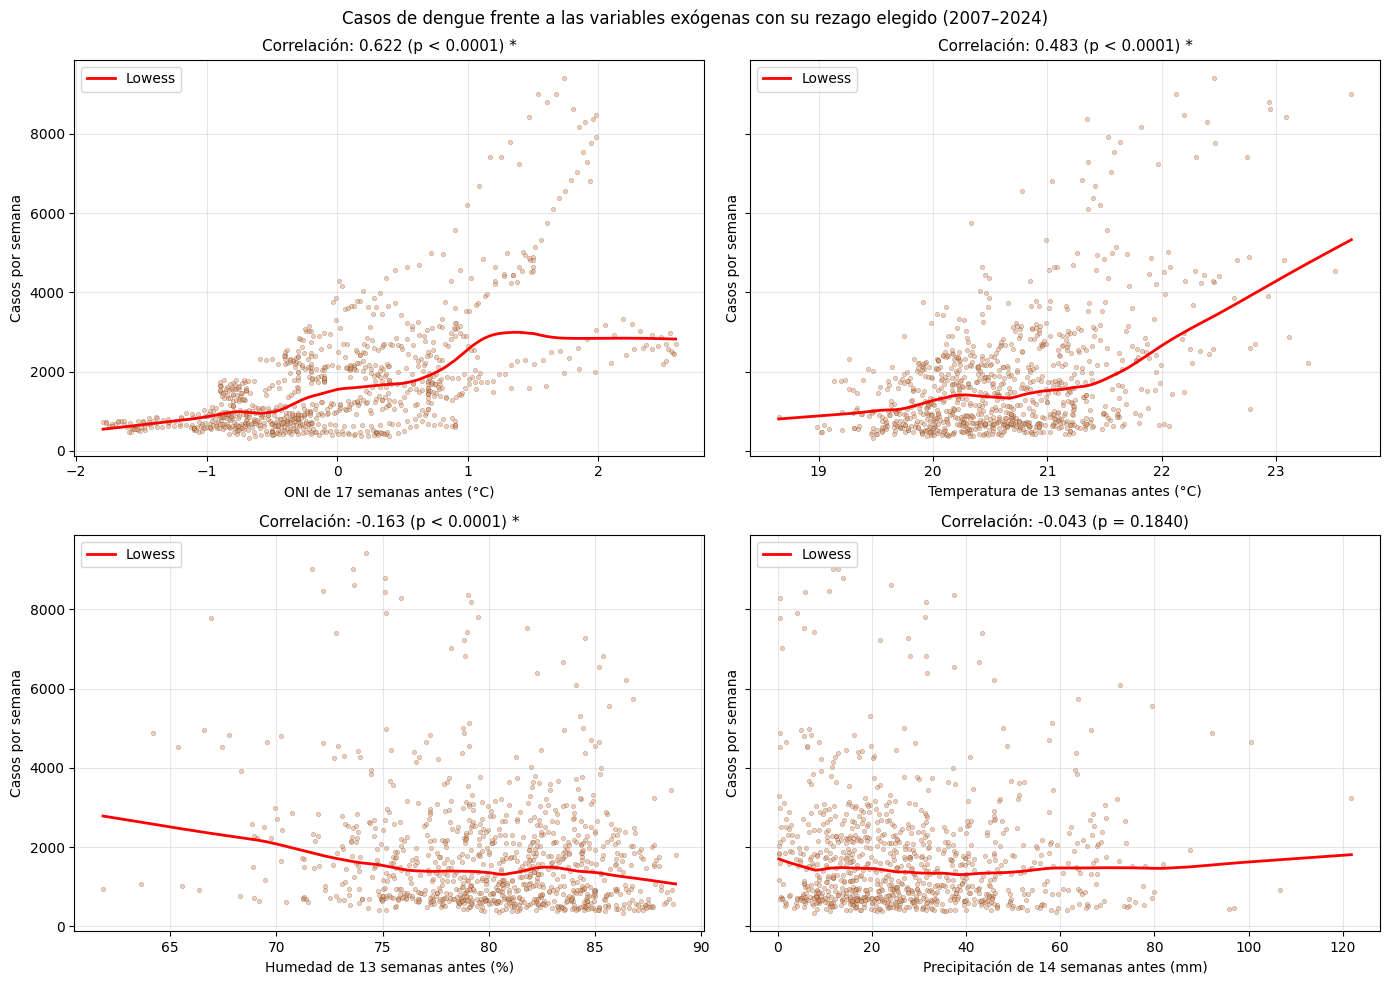

In [14]:
# Casos frente a cada variable exogena con el rezago elegido (entrenamiento 2007-2024)
exogenas_rezagadas = {
    f"ONI de {rezagos_2025['ONI']} semanas antes (°C)": oni_rezagado(rezagos_2025["ONI"])[train.index],
    f"Temperatura de {rezagos_2025['Temperatura']} semanas antes (°C)": clima_rezagado("Temperatura", rezagos_2025["Temperatura"])[train.index],
    f"Humedad de {rezagos_2025['Humedad']} semanas antes (%)": clima_rezagado("Humedad", rezagos_2025["Humedad"])[train.index],
    f"Precipitación de {rezagos_2025['Precipitacion']} semanas antes (mm)": clima_rezagado("Precipitacion", rezagos_2025["Precipitacion"])[train.index]}
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for ax, (nombre, x) in zip(axes.ravel(), exogenas_rezagadas.items()):
    ok = x.notna()
    r, p_valor = pearsonr(x[ok], serie_train[ok])
    ax.scatter(x[ok], serie_train[ok], s=10, alpha=0.5, edgecolors="k", linewidths=0.2, color="#E59866")
    suave = lowess(serie_train[ok], x[ok], frac=0.3)
    ax.plot(suave[:, 0], suave[:, 1], color="red", linewidth=2, label="Lowess")
    ax.set_title(f"Correlación: {r:.3f} ({'p < 0.0001' if p_valor < 0.0001 else f'p = {p_valor:.4f}'}){' *' if p_valor < 0.05 else ''}", fontsize=11)
    ax.set_xlabel(nombre)
    ax.set_ylabel("Casos por semana")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
fig.suptitle("Casos de dengue frente a las variables exógenas con su rezago elegido (2007–2024)")
plt.tight_layout()
plt.show()

**Interpretación**

- **ONI de 17 semanas antes:** r = 0.622, la relación más fuerte. La curva Lowess sube entre 0 y 1.3 °C y luego se aplana.
- **Temperatura de 13 semanas antes:** r = 0.483 (p < 0.0001). La curva es plana hasta unos 21.5 °C y sube después. Las semanas con más casos llegan después de trimestres muy calientes, que son los años de El Niño.
- **Humedad de 13 semanas antes:** r = −0.163 (p < 0.0001), una relación débil y negativa. Hay algo más de casos después de periodos secos, lo que también es coherente con El Niño.
- **Precipitación de 14 semanas antes:** r = −0.043 (p = 0.184), sin relación; la curva Lowess es plana.
- **Por qué la temperatura y la humedad dejan de ser significativas en M5:** en el modelo compiten con el ONI. Como El Niño sube la temperatura y baja la humedad, gran parte de su correlación con los casos pasa por el ONI. Que una variable esté correlacionada con los casos no implica que aporte información nueva una vez que el ONI ya está en el modelo.

### 5.2 Evaluación en 10 años de prueba (2016–2025)

Esta celda repite el experimento completo para cada año de prueba y cada horizonte. **Tarda entre 15 y 20 minutos**, porque en cada uno de los 20 casos se vuelven a elegir los rezagos y los órdenes de los seis modelos.

In [15]:
pronosticos, info_modelos, modelos_por_anio = {}, [], {}
for h in HORIZONTES:
    for anio in ANIOS_PRUEBA:
        pred, modelos = evaluar_anio(anio, h, modelos_2025 if (anio == 2025 and h == 4) else None)
        pred.insert(0, "Observado", serie_completa[pred.index].values)
        pronosticos[(h, anio)] = pred
        modelos_por_anio[(h, anio)] = modelos          # se guardan para el analisis GARCH (seccion 5.3.1)
        info_modelos.append({"Horizonte": h, "Año de prueba": anio, **{n: str(m[2]) for n, m in modelos.items()}})
    print(f"Horizonte de {h} semanas terminado")

print("\nÓRDENES ELEGIDOS EN CADA ENTRENAMIENTO")
print(pd.DataFrame(info_modelos).to_string(index=False))

Horizonte de 4 semanas terminado


Horizonte de 12 semanas terminado

ÓRDENES ELEGIDOS EN CADA ENTRENAMIENTO
 Horizonte  Año de prueba ARIMA_auto    M1_ONI M2_Temperatura M3_Humedad M4_ONI_Temp_Hum M5_ONI_Temp_Hum_Prec
         4           2016  (2, 1, 2) (3, 1, 1)      (2, 1, 2)  (2, 1, 2)       (2, 1, 2)            (1, 1, 3)
         4           2017  (4, 1, 1) (0, 1, 0)      (4, 1, 1)  (1, 1, 3)       (2, 1, 2)            (2, 1, 2)
         4           2018  (4, 1, 1) (0, 1, 0)      (4, 1, 1)  (4, 1, 1)       (4, 1, 0)            (2, 1, 2)
         4           2019  (4, 1, 1) (0, 1, 0)      (4, 1, 1)  (4, 1, 1)       (4, 1, 1)            (0, 1, 4)
         4           2020  (4, 1, 1) (5, 1, 1)      (4, 1, 1)  (4, 1, 1)       (3, 1, 4)            (5, 1, 1)
         4           2021  (5, 1, 0) (5, 1, 1)      (5, 1, 0)  (4, 1, 1)       (5, 1, 0)            (5, 1, 1)
         4           2022  (1, 0, 0) (5, 1, 1)      (5, 1, 0)  (4, 1, 1)       (5, 1, 0)            (5, 1, 1)
         4           2023  (1, 0, 0) (1, 0, 0)

In [16]:
nombres_modelos = [c for c in pronosticos[(4, 2025)].columns if c != "Observado"]

def tabla_resumen(h, anios):
    # RMSE, MAE y Diebold-Mariano frente al ingenuo, juntando las semanas de los años indicados
    junto = pd.concat([pronosticos[(h, a)] for a in anios])
    errores = junto[nombres_modelos].rsub(junto["Observado"], axis=0)
    filas = []
    for modelo in nombres_modelos:
        e = errores[modelo].values
        fila = {"Modelo": modelo, "RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e))}
        fila["RMSE frente al ingenuo (%)"] = (fila["RMSE"] / np.sqrt(np.mean(errores["M0_Ingenuo"].values**2)) - 1) * 100
        if modelo != "M0_Ingenuo":
            dm2, p2 = prueba_diebold_mariano(e, errores["M0_Ingenuo"].values, h=h, potencia=2)
            dm1, p1 = prueba_diebold_mariano(e, errores["M0_Ingenuo"].values, h=h, potencia=1)
            fila.update({"DM cuadrática": dm2, "p cuadrática": p2, "DM absoluta": dm1, "p absoluta": p1,
                         "Mejor que el ingenuo (5%)": "Sí" if (dm2 < 0 and p2 < 0.05) else "No"})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Modelo")

resumen = {}
for h in HORIZONTES:
    rmse_anio = pd.DataFrame({a: {m: np.sqrt(np.mean((pronosticos[(h, a)]["Observado"] - pronosticos[(h, a)][m])**2)) for m in nombres_modelos} for a in ANIOS_PRUEBA})
    print("=" * 110)
    print(f"HORIZONTE DE {h} SEMANAS: RMSE por año de prueba")
    print("=" * 110)
    print(rmse_anio.round(0).astype(int).to_string())
    resumen[h] = tabla_resumen(h, ANIOS_PRUEBA)
    print(f"\nLos 10 años juntos ({sum(len(pronosticos[(h, a)]) for a in ANIOS_PRUEBA)} semanas)")
    print(resumen[h].round({"RMSE": 1, "MAE": 1, "RMSE frente al ingenuo (%)": 1, "DM cuadrática": 2, "p cuadrática": 3, "DM absoluta": 2, "p absoluta": 3}).to_string())
    print(f"\nSolo 2025 ({len(pronosticos[(h, 2025)])} semanas)")
    print(tabla_resumen(h, [2025]).round({"RMSE": 1, "MAE": 1, "RMSE frente al ingenuo (%)": 1, "DM cuadrática": 2, "p cuadrática": 3, "DM absoluta": 2, "p absoluta": 3}).to_string())
    # Años en que cada modelo tiene menor RMSE que el ingenuo
    print(f"\nAños (de {len(ANIOS_PRUEBA)}) en que cada modelo tiene menor RMSE que el ingenuo: "
          f"{ {m: int((rmse_anio.loc[m] < rmse_anio.loc['M0_Ingenuo']).sum()) for m in nombres_modelos if m != 'M0_Ingenuo'} }\n")

HORIZONTE DE 4 SEMANAS: RMSE por año de prueba
                      2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
M0_Ingenuo             349    85   167   337   485   231   261   368   984   415
ARIMA_auto             359    78   148   337   469   224   255   405   817   428
M1_ONI                 309   105   156   348   474   211   247   348   813   446
M2_Temperatura         360    79   150   335   467   223   249   344   855   423
M3_Humedad             351    84   152   340   463   224   253   345   863   423
M4_ONI_Temp_Hum        320   103   156   341   468   210   251   310   833   439
M5_ONI_Temp_Hum_Prec   300   105   156   340   467   211   249   319   834   433

Los 10 años juntos (522 semanas)
                       RMSE    MAE  RMSE frente al ingenuo (%)  DM cuadrática  p cuadrática  DM absoluta  p absoluta Mejor que el ingenuo (5%)
Modelo                                                                                                                          

**Interpretación**

**Horizonte principal (4 semanas), los 10 años juntos**
- **Todos los modelos tienen menos error que el ingenuo.** El RMSE baja de 436.5 a entre 394.0 y 405.0: una reducción de 7 % a 10 %.
- **El mejor es M5 (ONI + clima local), con RMSE de 394.0 (9.7 % menos que el ingenuo).** Es el único cuya diferencia es **significativa al 5 %** con las dos pérdidas (p = 0.039 y 0.041).
- **Los modelos con solo ONI quedan en el borde:** M1 (p = 0.054) y M4 (p = 0.051) tienen casi el mismo RMSE (395.6).
- **Se cumple en la mayoría de los años:** cada modelo supera al ingenuo en 7 u 8 de los 10 años.

**Dónde gana y dónde pierde**
- **La ventaja es mayor en las epidemias:** en 2024 el RMSE baja de 984 a 834, y en 2016 de 349 a 300.
- **En los años tranquilos o de descenso no hay ventaja:** en 2017 (85 frente a 105) y en 2025 (415 frente a 433) el ingenuo es mejor.
- **Solo en 2025, el ingenuo tiene el menor RMSE** (415.0), sin diferencias significativas con ningún modelo (p entre 0.40 y 0.78). Es el mismo resultado de la primera versión del proyecto, que evaluaba solo ese año.

**Horizonte complementario (12 semanas)**
- Los modelos con ONI reducen el RMSE entre 6.5 % y 9.5 % (de 993.5 a 899.1 en M4), pero **ninguna diferencia es significativa** (p ≥ 0.10).
- A 3 meses los errores son más del doble que a 4 semanas (993.5 frente a 436.5 en el ingenuo): el pronóstico pierde precisión con rapidez.

**Advertencia sobre la significancia.** Se compararon seis modelos con el ingenuo y uno resultó significativo con p = 0.039. Con varias comparaciones, un resultado así puede aparecer por azar con más facilidad que en una sola prueba. La evidencia a favor del modelo con ONI es **moderada, no concluyente**; lo que la respalda es que la mejora es parecida en todos los modelos con ONI y se repite en 7 de los 10 años.

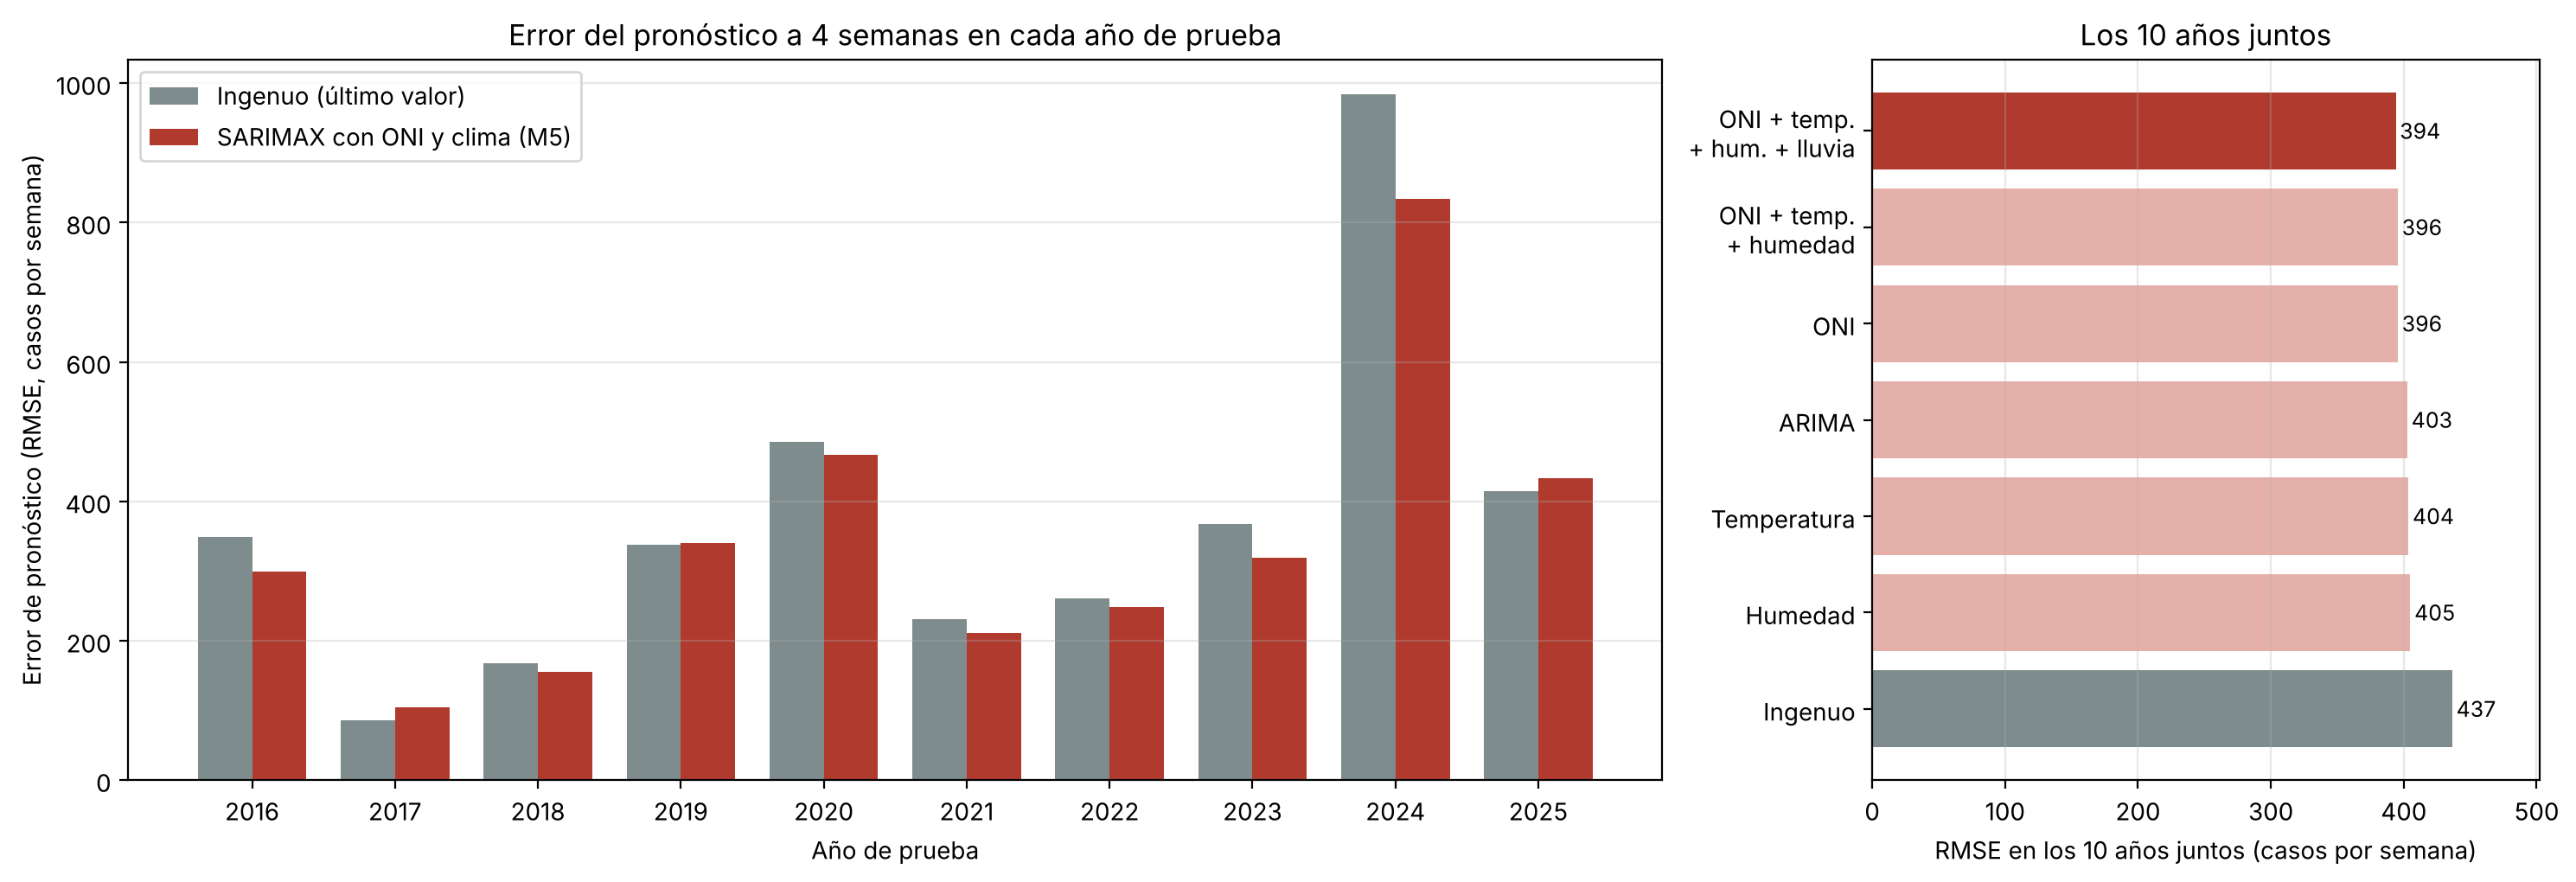

In [17]:
# Grafica: error del ingenuo frente a los modelos, por año de prueba (h = 4)
h = 4
rmse_anio = pd.DataFrame({a: {m: np.sqrt(np.mean((pronosticos[(h, a)]["Observado"] - pronosticos[(h, a)][m])**2)) for m in nombres_modelos} for a in ANIOS_PRUEBA})
mejor_candidato = resumen[4].drop(index="M0_Ingenuo")["RMSE"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.3, 1]})
ancho = 0.38
x = np.arange(len(ANIOS_PRUEBA))
axes[0].bar(x - ancho / 2, rmse_anio.loc["M0_Ingenuo"], width=ancho, color="#7F8C8D", label="Ingenuo (último valor)")
axes[0].bar(x + ancho / 2, rmse_anio.loc[mejor_candidato], width=ancho, color="#B03A2E", label=f"SARIMAX con ONI y clima ({mejor_candidato.split('_')[0]})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ANIOS_PRUEBA)
axes[0].set_xlabel("Año de prueba")
axes[0].set_ylabel("Error de pronóstico (RMSE, casos por semana)")
axes[0].set_title("Error del pronóstico a 4 semanas en cada año de prueba")
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)
etiquetas = {"M0_Ingenuo": "Ingenuo", "ARIMA_auto": "ARIMA", "M1_ONI": "ONI", "M2_Temperatura": "Temperatura", "M3_Humedad": "Humedad",
             "M4_ONI_Temp_Hum": "ONI + temp.\n+ humedad", "M5_ONI_Temp_Hum_Prec": "ONI + temp.\n+ hum. + lluvia"}
orden_barras = resumen[4]["RMSE"].sort_values(ascending=False)
colores_barras = ["#7F8C8D" if m == "M0_Ingenuo" else ("#B03A2E" if m == mejor_candidato else "#E6B0AA") for m in orden_barras.index]
axes[1].barh([etiquetas[m] for m in orden_barras.index], orden_barras.values, color=colores_barras)
for i, v in enumerate(orden_barras.values):
    axes[1].text(v + 3, i, f"{v:.0f}", va="center", fontsize=9)
axes[1].set_xlim(0, orden_barras.max() * 1.15)
axes[1].set_xlabel("RMSE en los 10 años juntos (casos por semana)")
axes[1].set_title("Los 10 años juntos")
axes[1].grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/2_error_por_anio.png", dpi=200, bbox_inches="tight")
plt.show()

**Pronóstico en la ventana de prueba 2025.** Se muestra el final del entrenamiento (2024), lo observado en 2025 y el pronóstico a 4 semanas de cada modelo. Cada punto pronosticado usa solo los datos disponibles 4 semanas antes (origen móvil), así que la gráfica muestra lo que cada modelo habría dicho en tiempo real.

RMSE a 4 semanas en 2025: M0_Ingenuo 415.0, M2_Temperatura 422.5, M3_Humedad 422.6, ARIMA_auto 428.2, M5_ONI_Temp_Hum_Prec 433.2, M4_ONI_Temp_Hum 438.8, M1_ONI 445.6


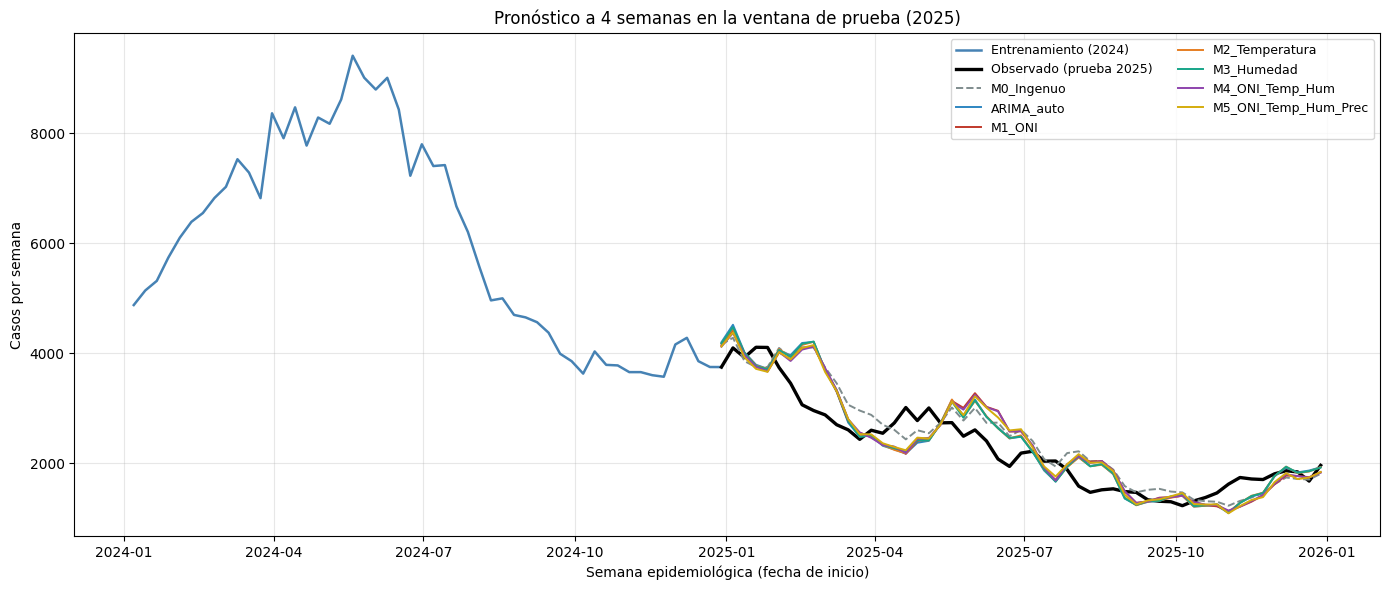

In [18]:
# Pronostico en la ventana de prueba 2025 (h = 4): todos los modelos frente a lo observado
pred_2025 = pronosticos[(4, 2025)]
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(serie_completa.loc["2024-01-01":"2024-12-31"], label="Entrenamiento (2024)", color="steelblue", linewidth=1.8)
ax.plot(pred_2025.index, pred_2025["Observado"], label="Observado (prueba 2025)", color="black", linewidth=2.4)
colores_modelos = {"M0_Ingenuo": "#7F8C8D", "ARIMA_auto": "#2E86C1", "M1_ONI": "#C0392B", "M2_Temperatura": "#E67E22",
                   "M3_Humedad": "#17A589", "M4_ONI_Temp_Hum": "#8E44AD", "M5_ONI_Temp_Hum_Prec": "#D4AC0D"}
for modelo, color in colores_modelos.items():
    if modelo in pred_2025.columns:
        ax.plot(pred_2025.index, pred_2025[modelo], label=modelo, color=color, linewidth=1.4, linestyle="--" if modelo == "M0_Ingenuo" else "-")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos por semana")
ax.set_title("Pronóstico a 4 semanas en la ventana de prueba (2025)")
ax.legend(ncol=2, fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rmse_2025 = {m: np.sqrt(np.mean((pred_2025["Observado"] - pred_2025[m])**2)) for m in colores_modelos if m in pred_2025.columns}
print("RMSE a 4 semanas en 2025:", ", ".join(f"{m} {v:.1f}" for m, v in sorted(rmse_2025.items(), key=lambda x: x[1])))

**Interpretación**

- **Todos los modelos siguen la curva observada con unas 4 semanas de retraso:** reaccionan tarde a los cambios de dirección.
  - En febrero de 2025 los casos bajaron de 4 106 a 2 955, pero el pronóstico de M5 siguió entre 3 900 y 4 150 por unas semanas.
  - Algo parecido pasa en los repuntes de mayo a julio.
  - Este retraso es normal en pronósticos a 4 semanas de una serie tan persistente: cada pronóstico usa datos de hace un mes.
- **Las líneas de los seis modelos ARIMA y SARIMAX casi se superponen.** En 2025 el ONI estuvo cerca de neutral (entre −0.6 y 0 °C), así que las variables exógenas casi no movieron el pronóstico.
- **En 2025, por sí solo, gana el ingenuo** (RMSE de 415.0 frente a 433.2 de M5), como ya se dijo en la sección 5.3. 2025 fue un año de descenso, y en las bajadas y los periodos tranquilos el ingenuo es difícil de superar.
- **Por eso la selección no se hace con un solo año.** En los 10 años de prueba (2016–2025), que incluyen subidas y bajadas, M5 tiene el menor error (RMSE 394.0 frente a 436.5 del ingenuo). Los modelos ganan sobre todo en las subidas, como 2023 y 2024 (sección 5.3).

### 5.3 Selección del modelo final y diagnóstico de residuos

In [19]:
# Regla fijada de antemano: menor RMSE a 4 semanas en los 10 años; reemplaza al ingenuo solo si la diferencia es significativa al 5 %
tab_sel = resumen[4].sort_values("RMSE")
candidato = tab_sel.index[0]
supera = candidato != "M0_Ingenuo" and tab_sel.loc[candidato, "DM cuadrática"] < 0 and tab_sel.loc[candidato, "p cuadrática"] < 0.05
nombre_final = candidato if supera else "M0_Ingenuo"
print(f"Modelo con menor RMSE a 4 semanas en los 10 años de prueba: {candidato} (RMSE {tab_sel.loc[candidato, 'RMSE']:.1f})")
if candidato != "M0_Ingenuo":
    print(f"Diebold-Mariano frente al ingenuo: DM = {tab_sel.loc[candidato, 'DM cuadrática']:.2f}, p = {tab_sel.loc[candidato, 'p cuadrática']:.3f} (pérdida cuadrática); "
          f"DM = {tab_sel.loc[candidato, 'DM absoluta']:.2f}, p = {tab_sel.loc[candidato, 'p absoluta']:.3f} (pérdida absoluta)")
print(f"¿Supera al ingenuo de forma significativa al 5 %? {'Sí' if supera else 'No'}")
print(f"MODELO FINAL: {nombre_final}\n")

# Diagnostico de residuos del modelo final y del ingenuo (entrenamiento 2007-2024)
ajuste_final_train = arima010 if nombre_final == "M0_Ingenuo" else modelos_2025[nombre_final][0]
tab_diagnostico = diagnostico_residuos({nombre_final: ajuste_final_train, "ARIMA(0,1,0)": arima010} if nombre_final != "M0_Ingenuo" else {"ARIMA(0,1,0)": arima010})
print(tab_diagnostico.T.apply(lambda col: col.map(lambda v: f"{v:.4g}" if isinstance(v, float) else v)).to_string())

Modelo con menor RMSE a 4 semanas en los 10 años de prueba: M5_ONI_Temp_Hum_Prec (RMSE 394.0)
Diebold-Mariano frente al ingenuo: DM = -2.07, p = 0.039 (pérdida cuadrática); DM = -2.05, p = 0.041 (pérdida absoluta)
¿Supera al ingenuo de forma significativa al 5 %? Sí
MODELO FINAL: M5_ONI_Temp_Hum_Prec

Modelo                            M5_ONI_Temp_Hum_Prec ARIMA(0,1,0)
Ljung-Box p (rezago 13)                       1.37e-07    8.612e-36
Ljung-Box p (rezago 26)                      8.901e-14     3.12e-40
Ljung-Box p (rezago 52)                      1.247e-17    8.151e-49
Ruido blanco                                        No           No
Jarque-Bera (estadístico)                         3880         4431
Jarque-Bera p                                        0            0
Shapiro-Wilk (estadístico)                      0.8872       0.8754
Shapiro-Wilk p                               1.375e-25    1.012e-26
Residuos normales                                   No           No
ARCH-LM (estadíst

**Interpretación**

- **Modelo final: M5, SARIMAX con ONI, temperatura, humedad y precipitación.** Según la regla fijada de antemano, tiene el menor RMSE a 4 semanas en los 10 años de prueba (394.0) y supera al ingenuo de forma significativa (DM = −2.07, p = 0.039).
- **Lo que hay que decir con honestidad:**
  - La ventaja sobre el modelo con solo ONI (M1, RMSE 395.6) es mínima, y las variables de clima local no son significativas. Un modelo solo con ONI sería casi igual de bueno y más simple.
  - Con la regla de la primera versión (menor RMSE solo en 2025) seguiría ganando el ingenuo.
- **Diagnóstico de residuos:** el modelo final mejora frente al ARIMA(0,1,0) (Jarque-Bera 3 880 frente a 4 431; ARCH-LM 175.3 frente a 194.2), pero **sigue fallando las tres pruebas**: los residuos no son ruido blanco, no son normales y tienen efecto ARCH. Los intervalos de pronóstico son aproximados: quedan angostos en las epidemias y anchos en los periodos tranquilos. La sección 5.3.1 corrige esto con un GARCH.
- **En la gráfica 2023–2025:** en la subida de 2023 y en la epidemia de 2024 el modelo se equivoca menos que el ingenuo (MAE de 234.2 frente a 261.3 y de 666.5 frente a 818.5). En el descenso de 2025 el ingenuo es un poco mejor (332.1 frente a 341.9).

**Diagnóstico gráfico de residuos.** `plot_diagnostics` muestra cuatro paneles: (1) residuos estandarizados en el tiempo, (2) histograma con la densidad normal, (3) gráfico Q-Q normal y (4) correlograma (ACF) de los residuos. Si el modelo está bien especificado, los residuos deben parecer **ruido blanco**: sin patrón en el tiempo, sin autocorrelación y, idealmente, con distribución normal.

La prueba de **Ljung-Box** (H₀: no hay autocorrelación hasta el rezago indicado) se aplica así: se descarta el primer residuo, que es el arranque de la diferencia ($d = 1$), y `model_df = p + q` descuenta los parámetros ARMA estimados de los grados de libertad. Por eso los p-valores pueden diferir un poco de la tabla anterior, que no hace ese ajuste.

Ljung-Box sobre los residuos de M5_ONI_Temp_Hum_Prec (model_df = 7):
        Estadístico Q   p-valor
Rezago                         
13              57.66 1.341e-10
26              118.5  2.08e-16
52              190.2 9.233e-20
Rezagos con autocorrelación fuera de la banda ±0.064: [12, 13, 14, 16, 19, 21, 23, 24, 25, 26, 39, 42, 47, 48, 52]
ACF de los residuos: rezago 13 = 0.203, 26 = 0.141, 52 = 0.138


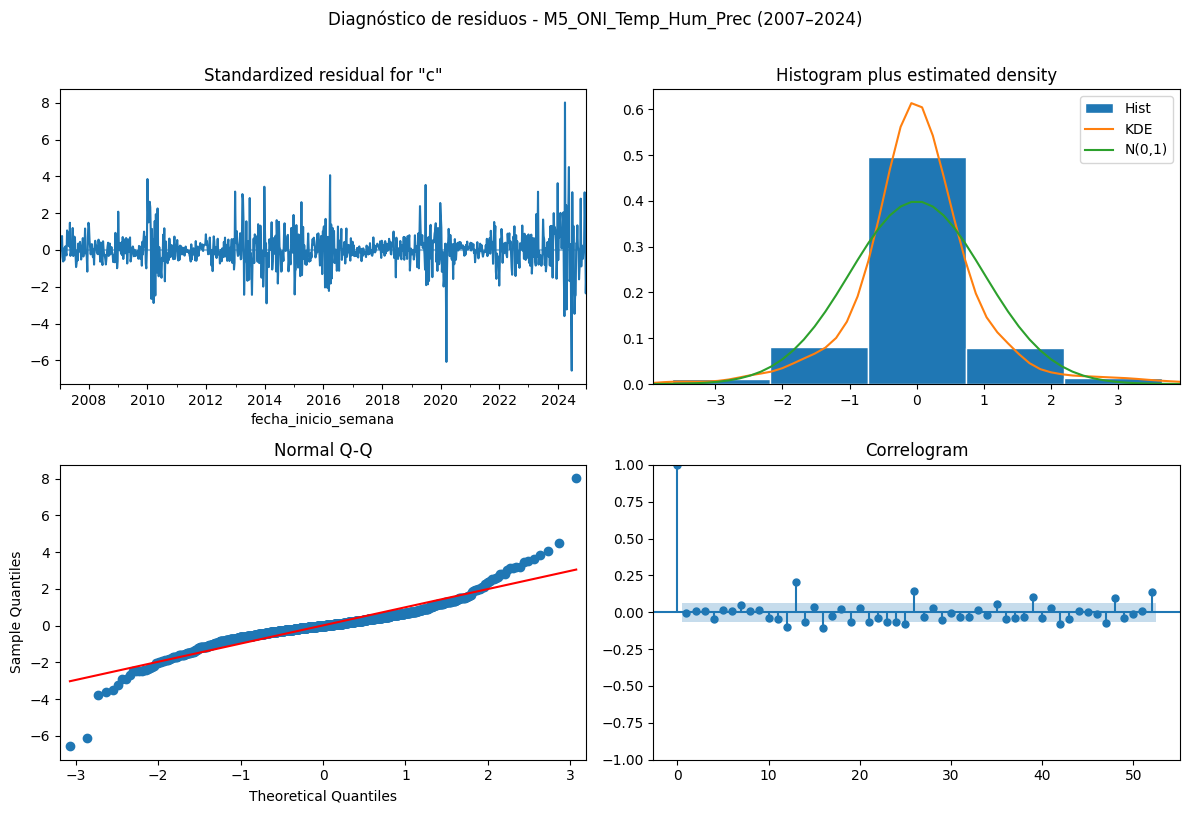

In [20]:
# Verificar ruido blanco del modelo final (entrenamiento 2007-2024)
def diagnostico_grafico(ajuste, nombre):
    ajuste.plot_diagnostics(figsize=(12, 8), lags=52)
    plt.suptitle(f"Diagnóstico de residuos - {nombre} (2007–2024)", y=1.01)
    plt.tight_layout()
    plt.show()
    # Ljung-Box: se descarta el primer residuo (arranque de la diferencia, d = 1)
    # y model_df descuenta los parametros ARMA estimados (p + q) de los grados de libertad
    p, d, q = ajuste.model.order
    lb = acorr_ljungbox(ajuste.resid[d:], lags=[13, 26, 52], model_df=p + q)
    lb.index.name = "Rezago"
    print(f"Ljung-Box sobre los residuos de {nombre} (model_df = {p + q}):")
    print(lb.rename(columns={"lb_stat": "Estadístico Q", "lb_pvalue": "p-valor"}).to_string(float_format=lambda v: f"{v:.4g}"))
    acf_res = acf_valores(ajuste.resid[d:], nlags=52)
    fuera = [k for k in range(1, 53) if abs(acf_res[k]) > 1.96 / np.sqrt(len(ajuste.resid) - d)]
    print(f"Rezagos con autocorrelación fuera de la banda ±{1.96 / np.sqrt(len(ajuste.resid) - d):.3f}: {fuera}")
    print(f"ACF de los residuos: rezago 13 = {acf_res[13]:.3f}, 26 = {acf_res[26]:.3f}, 52 = {acf_res[52]:.3f}")

diagnostico_grafico(ajuste_final_train, nombre_final)

**Interpretación**

- **Residuos estandarizados (panel 1):**
  - Están centrados en cero, pero su varianza no es constante: las oscilaciones son mucho mayores en las epidemias de 2010 y 2024.
  - Hay valores extremos en marzo de 2020 (−6.1, semana 11, al inicio de la pandemia de COVID-19, cuando la notificación cayó de golpe) y en la epidemia de 2024 (+8.0 a comienzos de abril, −6.6 en junio).
- **Histograma (panel 2) y gráfico Q-Q (panel 3):**
  - La densidad estimada es mucho más alta y estrecha que la normal, y los puntos del Q-Q se separan de la recta en los dos extremos: los residuos tienen **colas pesadas**.
  - Esto confirma lo que dicen Jarque-Bera (3 885.5) y Shapiro-Wilk: los residuos no son normales.
- **Correlograma (panel 4):**
  - La mayoría de los rezagos está dentro de la banda, pero sobresalen el 13 (0.203), el 26 (0.141) y el 52 (0.138), entre otros.
  - Son múltiplos de un trimestre y de un año: queda estructura estacional que el ARIMA no estacional no captura.
- **Ljung-Box con `model_df = 7`:** Q = 57.66 en el rezago 13, 118.5 en el 26 y 190.2 en el 52, todos con p < 0.001. **Los residuos no son ruido blanco.**
- **Qué significa para el proyecto:**
  - El pronóstico puntual se sigue pudiendo usar, porque su calidad se mide directamente en la evaluación fuera de la muestra (sección 5.2).
  - Los intervalos de pronóstico, en cambio, son aproximados, y por eso la sección 5.3.1 modela la varianza con un GARCH.
  - Una mejora posible a futuro es agregar términos estacionales (SARIMA con s = 52), que con datos semanales son costosos de estimar.

**Comparación con el ARIMA sin variables exógenas.** El mismo diagnóstico para el ARIMA de `auto_arima`, para ver si agregar el ONI y el clima mejora el comportamiento de los residuos.

Ljung-Box sobre los residuos de ARIMA(3, 1, 4) sin exógenas (model_df = 7):
        Estadístico Q   p-valor
Rezago                         
13              61.38 2.354e-11
26              116.4 5.137e-16
52              181.7 2.471e-18
Rezagos con autocorrelación fuera de la banda ±0.064: [12, 13, 16, 21, 25, 26, 39, 42, 47, 48, 52]
ACF de los residuos: rezago 13 = 0.219, 26 = 0.145, 52 = 0.124


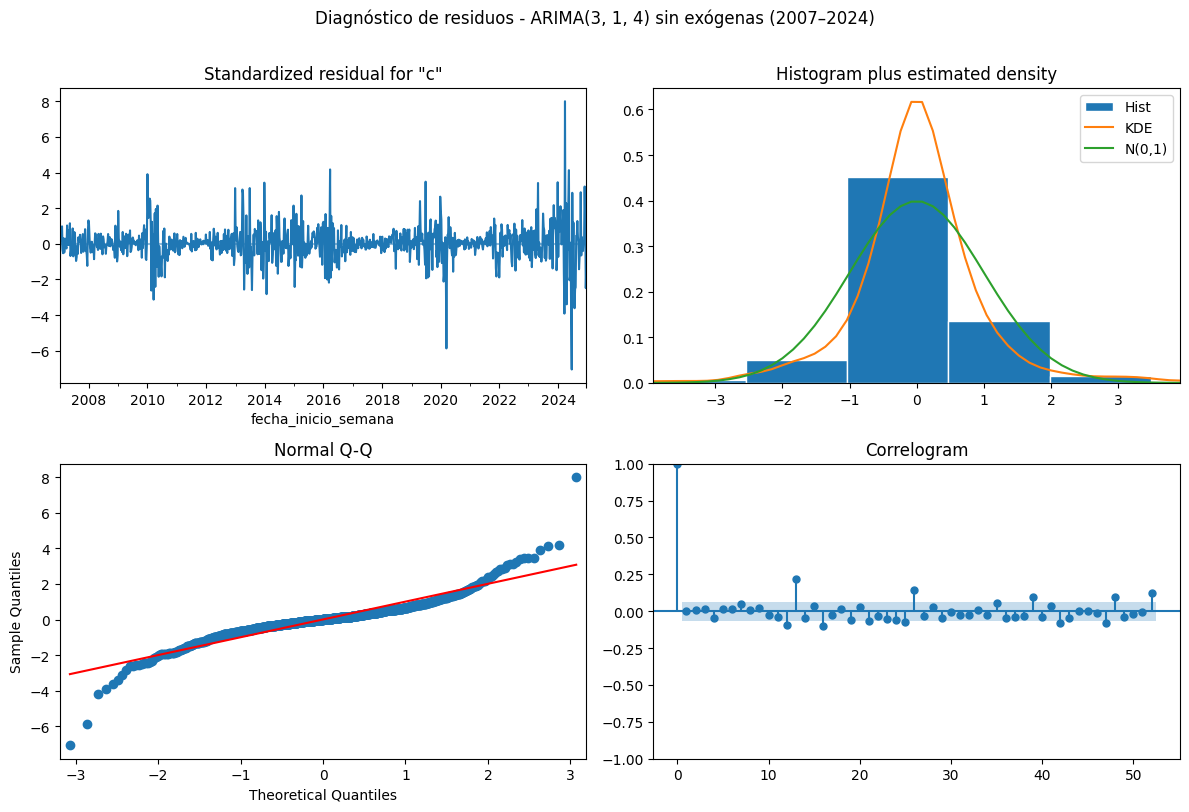

In [21]:
# Verificar ruido blanco del ARIMA sin variables exogenas (orden de auto_arima), para comparar
diagnostico_grafico(modelos_2025["ARIMA_auto"][0], f"ARIMA{modelos_2025['ARIMA_auto'][2]} sin exógenas")

**Interpretación**

- **Los residuos del ARIMA(3,1,4) sin exógenas son casi iguales a los de M5:**
  - tienen los mismos valores extremos (2020 y 2024), las mismas colas pesadas en el histograma y el Q-Q, y los mismos picos en el correlograma (0.219 en el rezago 13, 0.145 en el 26 y 0.124 en el 52);
  - Ljung-Box da Q = 61.38, 116.4 y 181.7 en los rezagos 13, 26 y 52, todos con p < 0.001.
- **Agregar el ONI y el clima cambia poco los residuos:**
  - La autocorrelación en el rezago 13 baja un poco (de 0.219 a 0.203, y Q de 61.4 a 57.7).
  - En el rezago 52 sube levemente (Q de 181.7 a 190.2).
  - Las exógenas mejoran el ajuste (menor AICc) y el pronóstico fuera de la muestra, pero no arreglan la estructura de los residuos.
- **Conclusión:** ninguno de los dos modelos deja residuos de ruido blanco, así que la familia ARIMA no capta toda la dinámica del dengue. Por eso el modelo final se elige con la evaluación fuera de la muestra (sección 5.2) y no con el diagnóstico de residuos, y sus intervalos se corrigen con el GARCH (sección 5.3.1).

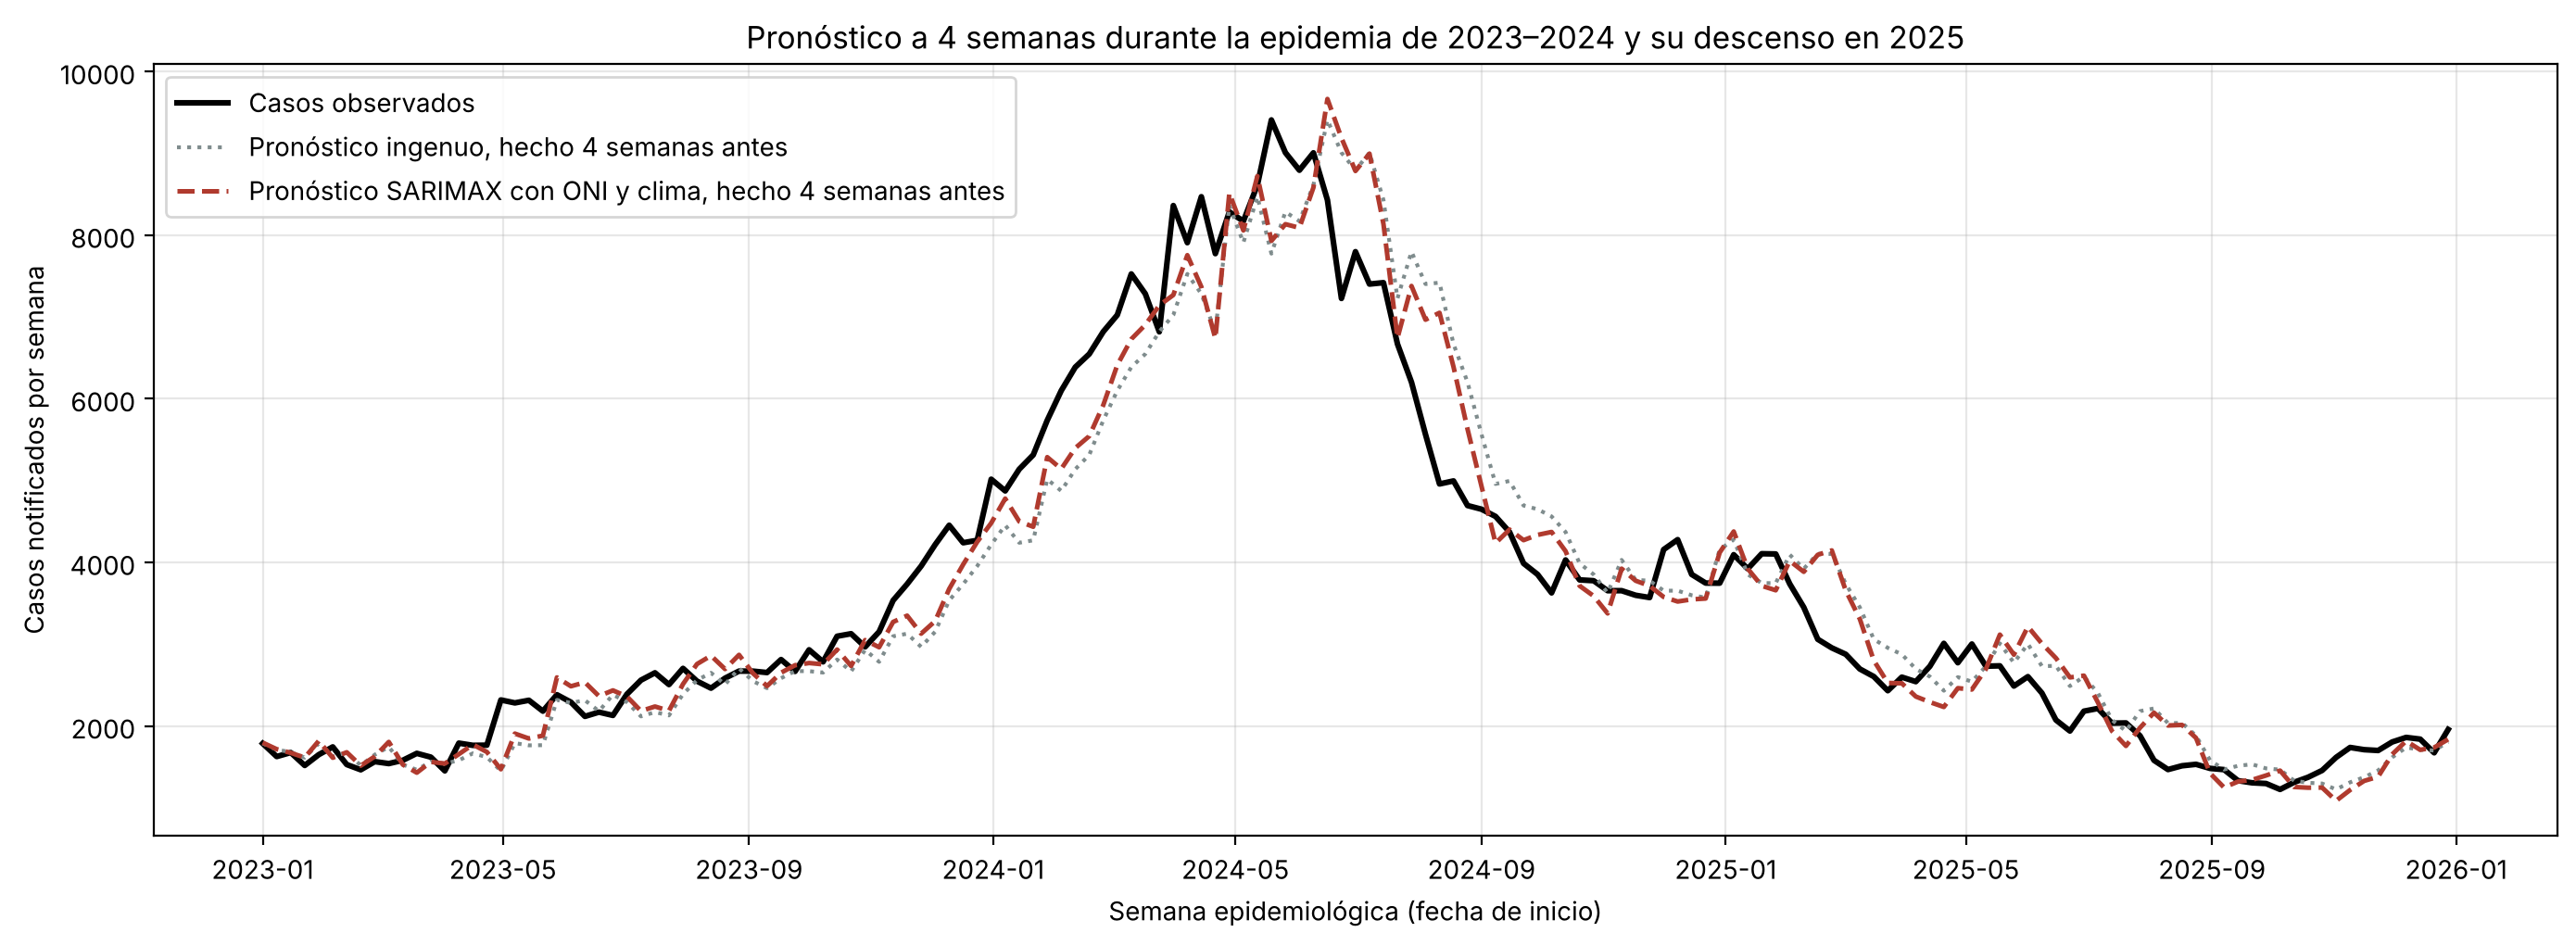

2023: MAE ingenuo 261.3 | MAE M5_ONI_Temp_Hum_Prec 234.2
2024: MAE ingenuo 818.5 | MAE M5_ONI_Temp_Hum_Prec 666.5
2025: MAE ingenuo 332.1 | MAE M5_ONI_Temp_Hum_Prec 341.9


In [22]:
# Grafica: pronostico a 4 semanas del modelo final y del ingenuo frente a lo observado, 2023-2025
junto = pd.concat([pronosticos[(4, a)] for a in [2023, 2024, 2025]])
modelo_grafica = nombre_final if nombre_final != "M0_Ingenuo" else mejor_candidato
fig, ax = plt.subplots(figsize=(14, 5.2))
ax.plot(junto.index, junto["Observado"], color="black", linewidth=2.2, label="Casos observados")
ax.plot(junto.index, junto["M0_Ingenuo"], color="#7F8C8D", linewidth=1.5, linestyle=":", label="Pronóstico ingenuo, hecho 4 semanas antes")
ax.plot(junto.index, junto[modelo_grafica], color="#B03A2E", linewidth=1.8, linestyle="--", label="Pronóstico SARIMAX con ONI y clima, hecho 4 semanas antes")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Pronóstico a 4 semanas durante la epidemia de 2023–2024 y su descenso en 2025")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/3_pronostico_epidemia.png", dpi=200, bbox_inches="tight")
plt.show()
for a in [2023, 2024, 2025]:
    p = pronosticos[(4, a)]
    print(f"{a}: MAE ingenuo {np.mean(np.abs(p['Observado'] - p['M0_Ingenuo'])):.1f} | MAE {modelo_grafica} {np.mean(np.abs(p['Observado'] - p[modelo_grafica])):.1f}")

### 5.3.1 Volatilidad: prueba ARCH y modelo GARCH(1,1)

El diagnóstico anterior muestra **efecto ARCH** en los residuos del modelo final (ARCH-LM p < 0.001): los errores son pequeños en los años tranquilos y muy grandes en las epidemias. El SARIMAX supone una varianza constante, así que sus intervalos tienen siempre el mismo ancho. Esta subsección:

1. Ajusta un **GARCH(1,1)** sobre los residuos del modelo final, con el entrenamiento de cada año de prueba de la sección 5.2.
2. Recalcula los intervalos del 80 % y del 95 % del pronóstico a 4 semanas con la varianza del GARCH.
3. Compara los intervalos con varianza constante y con GARCH en los 10 años de prueba: cobertura real, ancho medio e *interval score*, con la prueba de Diebold-Mariano.

> **Aclaración:** el GARCH **no compite** con los modelos de la sección 5.2 ni cambia la selección. El pronóstico puntual (los casos esperados) es exactamente el mismo; lo único que cambia es el ancho de los intervalos. Por eso no se compara con RMSE ni MAE, sino con medidas de la calidad de los intervalos.

Esta celda tarda 1 o 2 minutos.

In [23]:
from arch import arch_model
from statsmodels.tsa.arima_process import arma2ma

modelo_garch = nombre_final if nombre_final != "M0_Ingenuo" else mejor_candidato   # se aplica al modelo final
H_G = 4
Z = {80: stats.norm.ppf(0.90), 95: stats.norm.ppf(0.975)}

def pesos_psi(ajuste, h):
    # Pesos psi del ARIMA (incluye la diferencia si d = 1): el error a h semanas es sum_j psi_j * e_{t+h-j}
    ar = np.r_[1, -ajuste.arparams] if len(ajuste.arparams) else np.array([1.0])
    for _ in range(ajuste.model.order[1]):
        ar = np.convolve(ar, [1, -1])
    ma = np.r_[1, ajuste.maparams] if len(ajuste.maparams) else np.array([1.0])
    return arma2ma(ar, ma, lags=h)

def ajustar_garch(residuos):
    # GARCH(1,1) con media cero sobre los residuos del modelo, en cientos de casos (la optimizacion es mas estable)
    return arch_model(residuos / 100, mean="Zero", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")

def varianza_error_h(params, e_ultimo, s2_ultimo, psi, h):
    # Varianzas futuras: s2(t+1) = w + a*e(t)^2 + b*s2(t);  s2(t+k) = w + (a + b)*s2(t+k-1)
    w, a, b = params["omega"], params["alpha[1]"], params["beta[1]"]
    s2 = [w + a * e_ultimo**2 + b * s2_ultimo]
    for _ in range(1, h):
        s2.append(w + (a + b) * s2[-1])
    return sum(psi[j]**2 * s2[h - 1 - j] for j in range(h)) * 100**2      # varianza del error a h semanas (casos^2)

def puntaje_intervalo(y, li, ls, alpha):
    # Interval score (Gneiting y Raftery, 2007): ancho + penalizacion si el dato queda por fuera. Menor es mejor
    return (ls - li) + 2 / alpha * (li - y) * (y < li) + 2 / alpha * (y - ls) * (y > ls)

# Evaluacion en los 10 años de prueba: los mismos modelos y ventanas de la seccion 5.2
filas_garch, filas_parametros = [], []
for anio in ANIOS_PRUEBA:
    ajuste, X, orden = modelos_por_anio[(H_G, anio)][modelo_garch]
    y_hasta = serie_completa[datos["ANO"] <= anio]
    semanas = datos.index[datos["ANO"] == anio]
    # Residuos a 1 semana con los parametros del entrenamiento (cada residuo usa solo datos pasados)
    res_todo = ajuste.apply(y_hasta, exog=X.loc[y_hasta.index]) if X is not None else ajuste.apply(y_hasta)
    resid = res_todo.resid.iloc[5:]                       # se omiten las primeras semanas (arranque del filtro)
    resid_train = resid[resid.index < semanas[0]]
    garch = ajustar_garch(resid_train)                    # GARCH estimado solo con el entrenamiento
    p = garch.params
    filas_parametros.append({"Año de prueba": anio, "Orden": str(orden), "ARCH-LM p (residuos)": het_arch(resid_train, nlags=13)[1],
                             "omega": p["omega"], "alpha": p["alpha[1]"], "beta": p["beta[1]"], "alpha + beta": p["alpha[1]"] + p["beta[1]"]})
    s2_filtrada = arch_model(resid / 100, mean="Zero", vol="GARCH", p=1, q=1).fix(p.values).conditional_volatility**2
    psi = pesos_psi(ajuste, H_G)
    for semana in semanas:
        n_obs = serie_completa.index.get_loc(semana) - H_G + 1
        origen = serie_completa.index[n_obs - 1]          # ultima semana observada al pronosticar
        if X is None:
            f = ajuste.apply(serie_completa.iloc[:n_obs]).get_forecast(steps=H_G)
        else:
            f = ajuste.apply(serie_completa.iloc[:n_obs], exog=X.iloc[:n_obs]).get_forecast(steps=H_G, exog=X.iloc[n_obs:n_obs + H_G])
        ee_garch = np.sqrt(varianza_error_h(p, resid[origen] / 100, s2_filtrada[origen], psi, H_G))
        filas_garch.append({"Año": anio, "Semana": semana, "Observado": serie_completa[semana], "Pronóstico": f.predicted_mean.iloc[-1],
                            "EE constante": f.se_mean.iloc[-1], "EE GARCH": ee_garch})
eval_garch = pd.DataFrame(filas_garch).set_index("Semana")
print(f"Modelo: {modelo_garch} | ¿El pronóstico puntual es el mismo de la sección 5.2? "
      f"{'Sí' if np.allclose(eval_garch['Pronóstico'], pd.concat([pronosticos[(H_G, a)][modelo_garch] for a in ANIOS_PRUEBA])) else 'No'}\n")

print("PARÁMETROS DEL GARCH(1,1) EN CADA ENTRENAMIENTO")
print(pd.DataFrame(filas_parametros).to_string(index=False, formatters={"ARCH-LM p (residuos)": "{:.2e}".format, "omega": "{:.4f}".format,
      "alpha": "{:.3f}".format, "beta": "{:.3f}".format, "alpha + beta": "{:.4f}".format}))

def tabla_intervalos(df):
    filas = {}
    puntajes = {}
    for nombre, col in [("Varianza constante", "EE constante"), ("GARCH(1,1)", "EE GARCH")]:
        fila = {}
        for nivel in [80, 95]:
            li, ls = df["Pronóstico"] - Z[nivel] * df[col], df["Pronóstico"] + Z[nivel] * df[col]
            fila[f"Cobertura {nivel}% (%)"] = ((df["Observado"] >= li) & (df["Observado"] <= ls)).mean() * 100
            fila[f"Ancho medio {nivel}%"] = (ls - li).mean()
            puntajes[(nombre, nivel)] = puntaje_intervalo(df["Observado"], li, ls, 1 - nivel / 100).values
            fila[f"Interval score {nivel}%"] = puntajes[(nombre, nivel)].mean()
        filas[nombre] = fila
    tabla = pd.DataFrame(filas).T
    for nivel in [80, 95]:
        dm, pv = prueba_diebold_mariano(puntajes[("GARCH(1,1)", nivel)], puntajes[("Varianza constante", nivel)], h=H_G, potencia=1)
        tabla.loc["GARCH(1,1)", f"DM interval score {nivel}%"], tabla.loc["GARCH(1,1)", f"p {nivel}%"] = dm, pv
    return tabla

redondeo = {c: 1 for c in ["Cobertura 80% (%)", "Ancho medio 80%", "Interval score 80%", "Cobertura 95% (%)", "Ancho medio 95%", "Interval score 95%"]}
redondeo.update({"DM interval score 80%": 2, "p 80%": 4, "DM interval score 95%": 2, "p 95%": 4})
print(f"\nCALIDAD DE LOS INTERVALOS A {H_G} SEMANAS: los 10 años juntos ({len(eval_garch)} semanas)")
print(tabla_intervalos(eval_garch).round(redondeo).to_string())
print(f"\nSolo 2025 ({int((eval_garch['Año'] == 2025).sum())} semanas)")
print(tabla_intervalos(eval_garch[eval_garch["Año"] == 2025]).round(redondeo).to_string())

por_anio = pd.DataFrame({
    "Cobertura 95% constante": eval_garch.groupby("Año").apply(lambda g: (abs(g["Observado"] - g["Pronóstico"]) <= Z[95] * g["EE constante"]).mean() * 100),
    "Cobertura 95% GARCH": eval_garch.groupby("Año").apply(lambda g: (abs(g["Observado"] - g["Pronóstico"]) <= Z[95] * g["EE GARCH"]).mean() * 100),
    "Ancho 95% constante": eval_garch.groupby("Año")["EE constante"].mean() * 2 * Z[95],
    "Ancho 95% GARCH": eval_garch.groupby("Año")["EE GARCH"].mean() * 2 * Z[95]}).T
print("\nCOBERTURA (%) Y ANCHO MEDIO DEL INTERVALO DEL 95 % POR AÑO DE PRUEBA")
print(por_anio.round(0).astype(int).to_string())

Modelo: M5_ONI_Temp_Hum_Prec | ¿El pronóstico puntual es el mismo de la sección 5.2? Sí

PARÁMETROS DEL GARCH(1,1) EN CADA ENTRENAMIENTO
 Año de prueba     Orden ARCH-LM p (residuos)  omega alpha  beta alpha + beta
          2016 (1, 1, 3)             2.18e-14 0.0382 0.183 0.817       1.0000
          2017 (2, 1, 2)             1.28e-12 0.0632 0.208 0.785       0.9929
          2018 (2, 1, 2)             1.24e-14 0.0432 0.214 0.786       1.0000
          2019 (0, 1, 4)             1.35e-18 0.0360 0.204 0.796       1.0000
          2020 (5, 1, 1)             1.34e-18 0.0370 0.203 0.797       1.0000
          2021 (5, 1, 1)             3.94e-09 0.0387 0.215 0.785       1.0000
          2022 (5, 1, 1)             2.27e-10 0.0374 0.214 0.786       1.0000
          2023 (5, 1, 1)             6.78e-11 0.0349 0.210 0.790       1.0000
          2024 (5, 1, 1)             2.75e-10 0.0384 0.214 0.786       1.0000
          2025 (3, 1, 4)             2.19e-30 0.0361 0.219 0.781       1.0000

CALI

**Interpretación**

- **El efecto ARCH aparece en todos los entrenamientos** (ARCH-LM p < 10⁻⁸ en los 10), así que modelar la varianza está justificado.
- **α + β ≈ 1 en todos los entrenamientos** (1.0000 en nueve y 0.9929 en 2017). Es un GARCH "integrado" (IGARCH): un choque de volatilidad no se disipa y la varianza no vuelve a un nivel fijo. Para pronosticar 4 semanas no es un problema, pero a plazos largos los intervalos crecerían sin límite (ver limitaciones, 6.3).
- **Con varianza constante los intervalos prometen más de lo que cumplen:** el del 95 % atrapa el dato real en el 88.1 % de las semanas y el del 80 % en el 78.0 %. Con GARCH la cobertura queda muy cerca de lo prometido: 94.3 % y 81.2 %.
- **El *interval score* baja 37 % al 95 %** (de 2 807.7 a 1 761.4) y 17 % al 80 % (de 1 472.7 a 1 217.8). Las dos mejoras son significativas (Diebold-Mariano, p = 0.012 y p = 0.004).
- **Los intervalos con GARCH se adaptan al momento de la epidemia.** En 2024 el intervalo del 95 % con varianza constante solo atrapó el 48 % de las semanas; con GARCH, el 96 %, porque se ensancha (ancho medio de 3 151 casos frente a 1 123). En los años tranquilos se angosta: en 2017 mide 616 casos frente a 1 126.
- **En 2025 solo no hay diferencia significativa** (*interval score* de 2 128.3 frente a 2 255.2, p = 0.73), y el intervalo del 80 % se queda corto con los dos métodos (64.2 % y 69.8 %).
- **El costo:** en promedio los intervalos con GARCH son algo más anchos (1 304.8 frente a 1 126.3 casos al 95 %), porque se abren mucho en las epidemias.

GARCH(1,1) sobre los residuos de M5_ONI_Temp_Hum_Prec (entrenamiento 2007–2024)
          Coeficiente  p-valor
omega          0.0361   0.0148
alpha[1]       0.2188   0.0000
beta[1]        0.7812   0.0000
alpha + beta = 1.0000
AIC con varianza constante: 3650.8 | AIC con GARCH(1,1): 3098.9

                                     ARCH-LM p (13 rezagos) Ljung-Box p de los cuadrados (13 rezagos) Jarque-Bera (estadístico)
Residuos del modelo                               2.193e-30                                 1.017e-80                    3864.9
Residuos estandarizados por el GARCH                0.09029                                   0.09571                     280.7

Correlación entre la volatilidad estimada por el GARCH y el nivel de casos de la semana anterior: 0.843


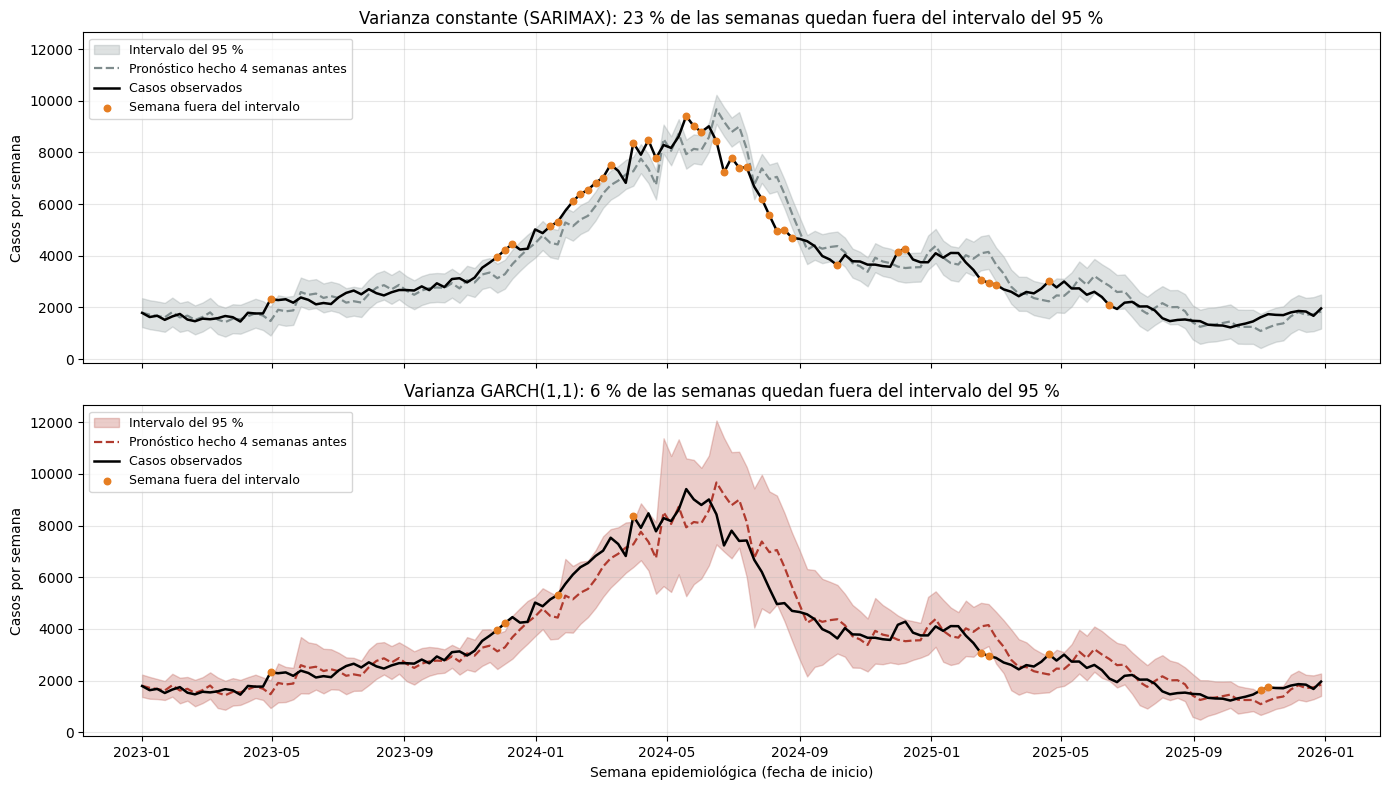

In [24]:
# Diagnostico del GARCH con el entrenamiento mas largo (2007-2024): ¿elimina el efecto ARCH?
ajuste_g, X_g, _ = modelos_2025[modelo_garch]
resid_g = ajuste_g.resid.iloc[5:]
garch_2024 = ajustar_garch(resid_g)
z_g = resid_g / 100 / garch_2024.conditional_volatility                 # residuos estandarizados
print(f"GARCH(1,1) sobre los residuos de {modelo_garch} (entrenamiento 2007–2024)")
print(pd.DataFrame({"Coeficiente": garch_2024.params, "p-valor": garch_2024.pvalues}).round(4).to_string())
print(f"alpha + beta = {garch_2024.params['alpha[1]'] + garch_2024.params['beta[1]']:.4f}")
aic_constante = arch_model(resid_g / 100, mean="Zero", vol="Constant").fit(disp="off").aic
print(f"AIC con varianza constante: {aic_constante:.1f} | AIC con GARCH(1,1): {garch_2024.aic:.1f}\n")

diag_g = pd.DataFrame({
    "Residuos del modelo": [het_arch(resid_g, nlags=13)[1], acorr_ljungbox(resid_g**2, lags=[13])["lb_pvalue"].iloc[0], stats.jarque_bera(resid_g)[0]],
    "Residuos estandarizados por el GARCH": [het_arch(z_g, nlags=13)[1], acorr_ljungbox(z_g**2, lags=[13])["lb_pvalue"].iloc[0], stats.jarque_bera(z_g)[0]]},
    index=["ARCH-LM p (13 rezagos)", "Ljung-Box p de los cuadrados (13 rezagos)", "Jarque-Bera (estadístico)"])
print(diag_g.T.to_string(formatters={"ARCH-LM p (13 rezagos)": "{:.4g}".format, "Ljung-Box p de los cuadrados (13 rezagos)": "{:.4g}".format,
                                      "Jarque-Bera (estadístico)": "{:.1f}".format}))
volatilidad = garch_2024.conditional_volatility * 100
print(f"\nCorrelación entre la volatilidad estimada por el GARCH y el nivel de casos de la semana anterior: "
      f"{np.corrcoef(volatilidad.iloc[1:], serie_train.shift(1).loc[volatilidad.index].iloc[1:])[0, 1]:.3f}")

# Grafica: intervalos del 95 % con varianza constante y con GARCH, 2023-2025
g = eval_garch[eval_garch["Año"] >= 2023]
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, col, titulo, color in [(axes[0], "EE constante", "Varianza constante (SARIMAX)", "#7F8C8D"), (axes[1], "EE GARCH", "Varianza GARCH(1,1)", "#B03A2E")]:
    li, ls = g["Pronóstico"] - Z[95] * g[col], g["Pronóstico"] + Z[95] * g[col]
    fuera = (g["Observado"] < li) | (g["Observado"] > ls)
    ax.fill_between(g.index, li, ls, color=color, alpha=0.25, label="Intervalo del 95 %")
    ax.plot(g.index, g["Pronóstico"], color=color, linewidth=1.6, linestyle="--", label="Pronóstico hecho 4 semanas antes")
    ax.plot(g.index, g["Observado"], color="black", linewidth=1.8, label="Casos observados")
    ax.scatter(g.index[fuera], g["Observado"][fuera], color="#E67E22", zorder=5, s=22, label="Semana fuera del intervalo")
    ax.set_title(f"{titulo}: {fuera.mean() * 100:.0f} % de las semanas quedan fuera del intervalo del 95 %")
    ax.set_ylabel("Casos por semana")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(True, alpha=0.3)
axes[1].set_xlabel("Semana epidemiológica (fecha de inicio)")
plt.tight_layout()
plt.savefig("figuras/4_intervalos_garch.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación**

- **El GARCH describe mucho mejor la varianza de los residuos:** el AIC baja de 3 650.8 a 3 098.9, y α = 0.219 y β = 0.781 son muy significativos.
- **Elimina el efecto ARCH:** en los residuos estandarizados por el GARCH ya no se rechaza la prueba ARCH-LM (p = 0.090) ni la de Ljung-Box sobre los cuadrados (p = 0.096). En los residuos originales los dos p-valores son prácticamente cero.
- **Los residuos siguen sin ser normales,** aunque mucho menos (Jarque-Bera baja de 3 864.9 a 280.7). Por eso los intervalos siguen siendo aproximados, aunque mejores.
- **La volatilidad sigue al nivel de casos:** su correlación con los casos de la semana anterior es 0.843. El error crece cuando hay más casos. Esto sugiere una alternativa más simple que el GARCH: modelar el **logaritmo de los casos** (ver próximos pasos).
- **En la gráfica 2023–2025:** con varianza constante el 23 % de las semanas quedan fuera del intervalo del 95 %, casi todas en la epidemia de 2024; con GARCH, solo el 6 %.

### 5.4 Pronóstico de 2026-SE01 a 2026-SE04

El modelo final se **reestima con toda la serie (2007–2025)**, manteniendo los rezagos y el orden elegidos con el entrenamiento 2007–2024, y se pronostican las 4 semanas siguientes con intervalos del 80 % y del 95 %. Como los rezagos son de 5 semanas o más, los valores de las variables exógenas que se necesitan ya están observados.

Variables exógenas usadas para el pronóstico (ya observadas):
             ONI  Temperatura  Humedad  Precipitacion
2026-01-04 -0.37        20.58    82.40          31.14
2026-01-11 -0.40        20.04    84.58          62.98
2026-01-18 -0.44        20.56    85.14          50.51
2026-01-25 -0.49        20.67    84.90          39.89

Modelo final: M5_ONI_Temp_Hum_Prec, ARIMA(3, 1, 4), reestimado con 992 semanas
               Coeficiente  p-valor
ONI                 658.36   0.0001
Temperatura           8.19   0.5753
Humedad              -2.31   0.3302
Precipitacion        -0.37   0.1974

Última semana observada: 2025-SE53, 1957 casos. Inicio de 2026-SE01: 2026-01-04
   Semana  Pronóstico  LI 80%  LS 80%  LI 95%  LS 95%  Ingenuo
2026-SE01      1891.0  1670.0  2112.0  1553.0  2229.0   1957.0
2026-SE02      1907.0  1607.0  2208.0  1448.0  2367.0   1957.0
2026-SE03      1868.0  1494.0  2242.0  1296.0  2440.0   1957.0
2026-SE04      1883.0  1446.0  2320.0  1215.0  2551.0   1957.0


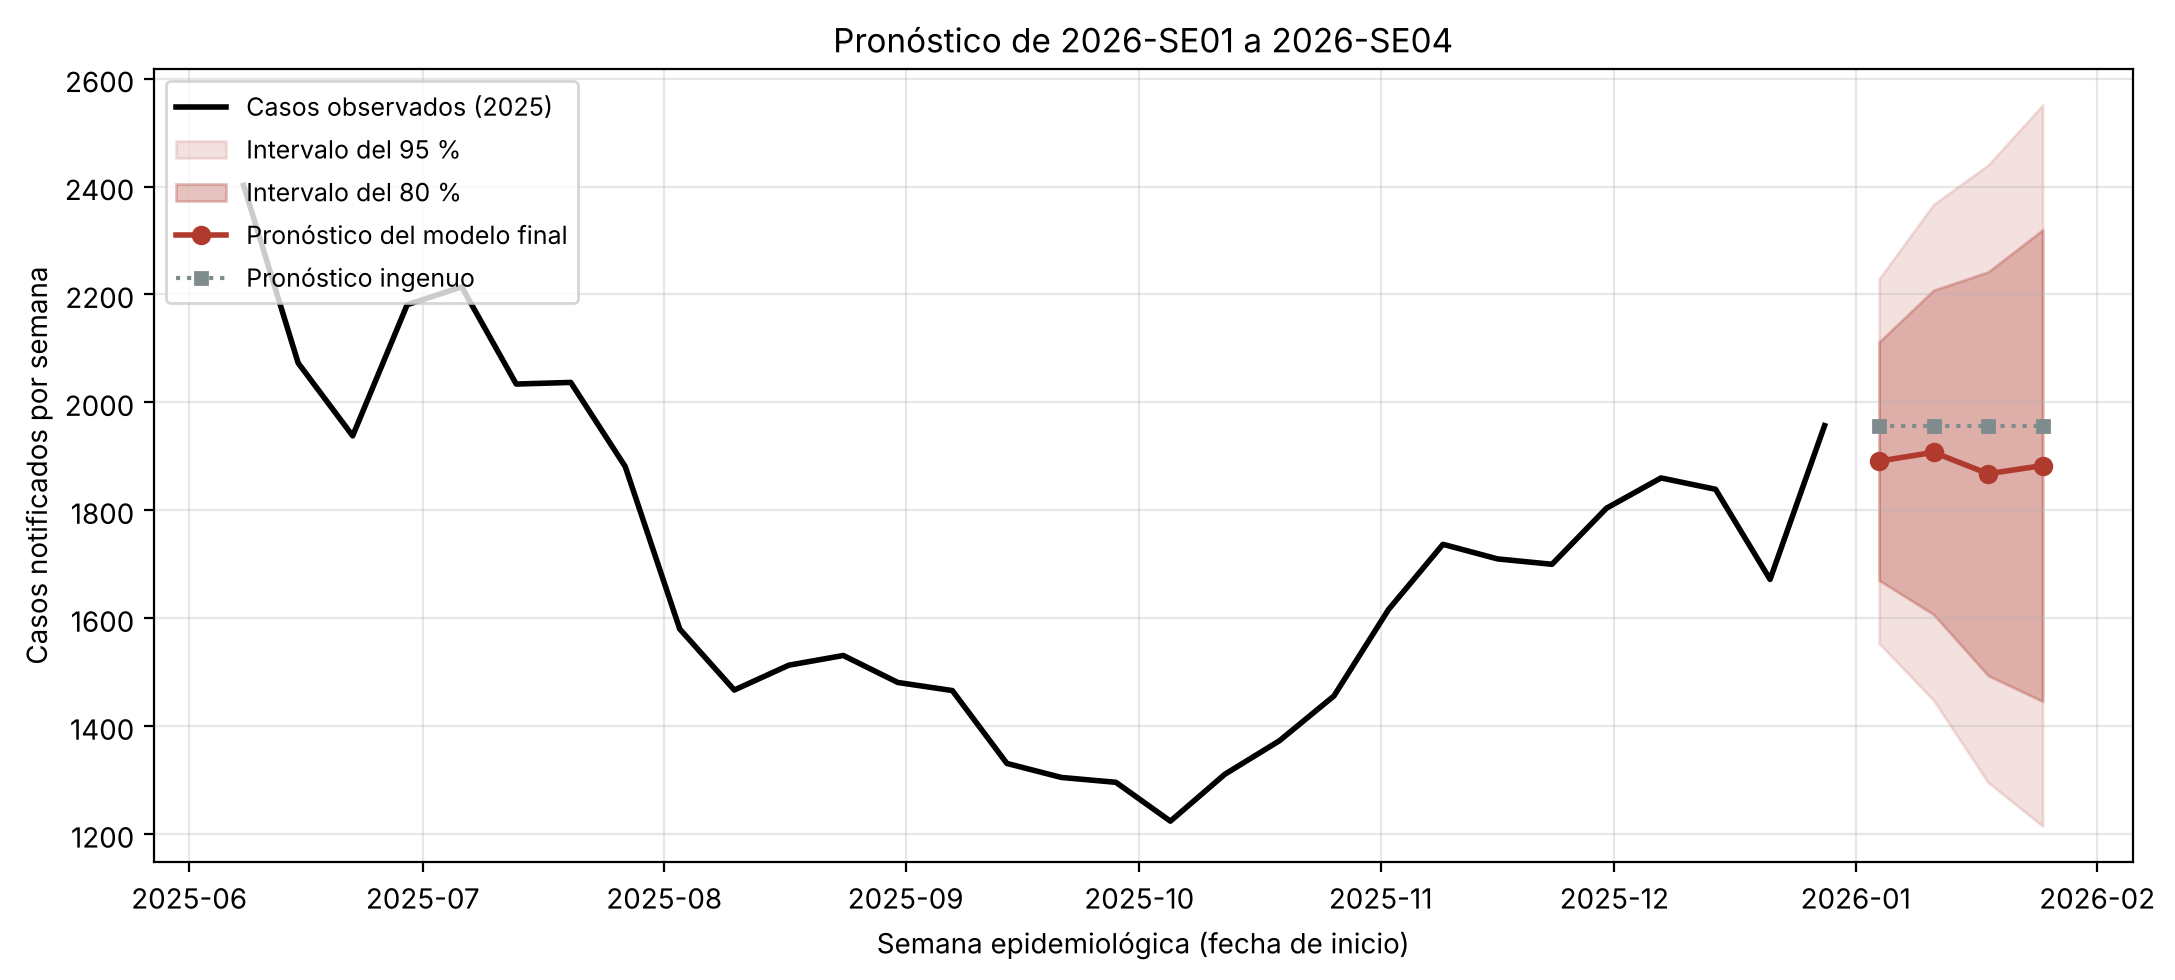

In [25]:
h_final = 4
fechas_futuras = pd.date_range(datos.index[-1] + pd.Timedelta(weeks=1), periods=h_final, freq="W-SUN")
if nombre_final == "M0_Ingenuo":
    modelo_final = ARIMA(serie_completa, order=(0, 1, 0)).fit()
    pron_final = modelo_final.get_forecast(steps=h_final)
else:
    _, X_final, orden_final = modelos_2025[nombre_final]
    modelo_final = ARIMA(serie_completa, exog=X_final.loc[serie_completa.index], order=orden_final).fit()
    X_futuro = pd.concat([oni_rezagado(rezagos_2025[v], fechas_futuras) if v == "ONI" else clima_rezagado(v, rezagos_2025[v], fechas_futuras) for v in X_final.columns], axis=1)
    print("Variables exógenas usadas para el pronóstico (ya observadas):")
    print(X_futuro.round(2).to_string())
    pron_final = modelo_final.get_forecast(steps=h_final, exog=X_futuro)
print(f"\nModelo final: {nombre_final}, ARIMA{modelo_final.model.order}, reestimado con {int(modelo_final.nobs)} semanas")
if nombre_final != "M0_Ingenuo":
    print(pd.DataFrame({"Coeficiente": modelo_final.params[X_final.columns].round(2), "p-valor": modelo_final.pvalues[X_final.columns].round(4)}).to_string())

ic80, ic95 = pron_final.conf_int(alpha=0.20), pron_final.conf_int(alpha=0.05)
tab_pronostico = pd.DataFrame({"Semana": [f"2026-SE{s:02d}" for s in range(1, h_final + 1)], "Pronóstico": pron_final.predicted_mean.values,
                               "LI 80%": ic80.iloc[:, 0].values, "LS 80%": ic80.iloc[:, 1].values, "LI 95%": ic95.iloc[:, 0].values, "LS 95%": ic95.iloc[:, 1].values,
                               "Ingenuo": serie_completa.iloc[-1]}, index=fechas_futuras)
print(f"\nÚltima semana observada: 2025-SE53, {serie_completa.iloc[-1]:.0f} casos. Inicio de 2026-SE01: {inicio_anio_epidemiologico(2026).date()}")
print(tab_pronostico.round(0).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
ultimas = serie_completa.iloc[-30:]
ax.plot(ultimas.index, ultimas, color="black", linewidth=2, label="Casos observados (2025)")
ax.fill_between(fechas_futuras, tab_pronostico["LI 95%"], tab_pronostico["LS 95%"], color="#B03A2E", alpha=0.15, label="Intervalo del 95 %")
ax.fill_between(fechas_futuras, tab_pronostico["LI 80%"], tab_pronostico["LS 80%"], color="#B03A2E", alpha=0.30, label="Intervalo del 80 %")
ax.plot(fechas_futuras, tab_pronostico["Pronóstico"], color="#B03A2E", marker="o", linewidth=2, label="Pronóstico del modelo final")
ax.plot(fechas_futuras, tab_pronostico["Ingenuo"], color="#7F8C8D", linestyle=":", marker="s", markersize=4, label="Pronóstico ingenuo")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Pronóstico de 2026-SE01 a 2026-SE04")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación**

- **Pronóstico:** para 2026-SE01 a 2026-SE04 el modelo final espera entre 1 868 y 1 907 casos por semana, un poco menos que los 1 957 de la última semana observada (que es el pronóstico del ingenuo).
- **Por qué pronostica menos que el ingenuo:** el ONI de hace 17 semanas es negativo (entre −0.37 y −0.49, condiciones de La Niña débil), y en el modelo un ONI más bajo se asocia con menos casos.
- **Incertidumbre:** el intervalo del 95 % va de 1 553 a 2 229 casos en la semana 1 y de 1 215 a 2 551 en la semana 4. Los intervalos son aproximados, porque los residuos no son normales. Abajo se recalculan con GARCH.
- **El ONI sigue siendo la única variable significativa** al reestimar con toda la serie (658.36, p < 0.001); la temperatura, la humedad y la precipitación no lo son.
- **Uso en salud pública:** el pronóstico indica un inicio de 2026 estable, sin señales de una nueva subida en el primer periodo epidemiológico. Se debe actualizar cada semana con el dato nuevo.

**Intervalos del pronóstico 2026 con GARCH.** Se ajusta el GARCH(1,1) sobre los residuos del modelo final reestimado con toda la serie (2007–2025) y se recalculan los intervalos. El pronóstico puntual no cambia.

In [26]:
# Intervalos del pronostico 2026 con varianza GARCH(1,1), estimado sobre los residuos del modelo final reestimado (2007-2025)
resid_final = modelo_final.resid.iloc[5:]
garch_final = ajustar_garch(resid_final)
e_ultimo, s2_ultimo = resid_final.iloc[-1] / 100, garch_final.conditional_volatility.iloc[-1]**2
ee_garch_2026 = np.array([np.sqrt(varianza_error_h(garch_final.params, e_ultimo, s2_ultimo, pesos_psi(modelo_final, k), k)) for k in range(1, h_final + 1)])
ee_constante_2026 = pron_final.se_mean.values
media_2026 = pron_final.predicted_mean.values
tab_garch_2026 = pd.DataFrame({"Semana": tab_pronostico["Semana"].values, "Pronóstico": media_2026,
                               "EE constante": ee_constante_2026, "EE GARCH": ee_garch_2026,
                               "LI 80% GARCH": media_2026 - Z[80] * ee_garch_2026, "LS 80% GARCH": media_2026 + Z[80] * ee_garch_2026,
                               "LI 95% GARCH": media_2026 - Z[95] * ee_garch_2026, "LS 95% GARCH": media_2026 + Z[95] * ee_garch_2026})
print(f"GARCH(1,1) sobre los residuos del modelo final (2007–2025): alpha = {garch_final.params['alpha[1]']:.3f}, beta = {garch_final.params['beta[1]']:.3f}, "
      f"alpha + beta = {garch_final.params['alpha[1]'] + garch_final.params['beta[1]']:.4f}")
print(f"Desviación estándar del error a 1 semana: constante {ee_constante_2026[0]:.0f} casos | GARCH al final de 2025 {ee_garch_2026[0]:.0f} casos\n")
print(tab_garch_2026.round(0).to_string(index=False))

GARCH(1,1) sobre los residuos del modelo final (2007–2025): alpha = 0.213, beta = 0.787, alpha + beta = 1.0000
Desviación estándar del error a 1 semana: constante 172 casos | GARCH al final de 2025 159 casos

   Semana  Pronóstico  EE constante  EE GARCH  LI 80% GARCH  LS 80% GARCH  LI 95% GARCH  LS 95% GARCH
2026-SE01      1891.0         172.0     159.0        1688.0        2095.0        1580.0        2203.0
2026-SE02      1907.0         234.0     217.0        1629.0        2186.0        1482.0        2333.0
2026-SE03      1868.0         292.0     271.0        1521.0        2215.0        1337.0        2399.0
2026-SE04      1883.0         341.0     317.0        1476.0        2290.0        1261.0        2505.0


**Interpretación**

- **Al final de 2025 la volatilidad estimada es algo menor que la varianza constante del modelo** (desviación estándar del error a 1 semana: 159 casos con GARCH frente a 172), porque fue un periodo de casos moderados y cambios pequeños. Por eso los intervalos con GARCH son un poco **más angostos**: al 95 %, de 1 580 a 2 203 casos en la semana 1 y de 1 261 a 2 505 en la semana 4 (frente a 1 553–2 229 y 1 215–2 551 con varianza constante).
- **Según la evaluación de la sección 5.3.1, estos intervalos son más confiables** que los de varianza constante. Si los casos empezaran a subir, el GARCH ensancharía los intervalos de las semanas siguientes.

## Conceptos

Resumen de los estadísticos, pruebas, gráficos y criterios de información que se usan en el cuaderno: qué mide cada uno, qué hipótesis prueba y cómo se lee.

**Tabla A. Estadísticos, pruebas y gráficos**

| Estadístico o gráfico | Qué mide o calcula | Prueba de hipótesis (H₀ / H₁) o descripción del gráfico | Rango y lectura | Sección |
| :--- | :--- | :--- | :--- | :--- |
| Media, mediana, desviación estándar | Nivel típico de casos por semana y su dispersión | Descriptivo, no es una prueba | Media y mediana ≥ 0; desviación ≥ 0. Si la media es mucho mayor que la mediana, hay semanas extremas (epidemias) | 2 |
| Coeficiente de variación (CV) | Dispersión relativa: desviación estándar ÷ media × 100 | Descriptivo | ≥ 0 %. Más alto = casos más variables dentro del año | 2 |
| Correlación de Pearson (casos vs. ONI rezagado) | Fuerza de la relación lineal entre los casos y el ONI de *k* semanas antes | Descriptivo; se usa para ver con qué rezago se relacionan más | De −1 a 1. Cerca de 1: relación positiva fuerte; 0: sin relación lineal. No prueba causalidad. Con semanas consecutivas su p-valor exagera la significancia | 3.1, 3.1.2, 5.1 |
| Gráfico de la serie con ONI y años epidémicos | Cómo cambian los casos en el tiempo y si las epidemias coinciden con El Niño | Gráfico: casos por semana (línea), ONI (área) y periodos epidémicos sombreados | No aplica | 3.1 |
| Gráfico de las cinco series | Casos, ONI, temperatura, humedad y precipitación en el mismo eje de tiempo | Gráfico: un panel por serie, 2007–2025; líneas punteadas en ±0.5 °C del ONI (umbrales de El Niño y La Niña) | No aplica | 3.1 |
| Descomposición STL | Separa la serie en tendencia, estacionalidad y residuo: $y_t = T_t + S_t + R_t$ | Gráfico de cuatro paneles: serie, tendencia, estacionalidad y residuo. `period=52`, `seasonal=53` | No aplica. Un residuo grande indica cambios que ni la tendencia ni la estacionalidad explican | 3.1.1 |
| Fuerza de la tendencia ($F_T$) y de la estacionalidad ($F_S$) | Qué parte de la variación de la serie explica cada componente de la STL | Descriptivo (Hyndman y Athanasopoulos) | De 0 a 1. Cerca de 1: componente fuerte; cerca de 0: casi no existe | 3.1.1 |
| Gráfico de dispersión con curva Lowess | Forma de la relación entre los casos y una variable exógena rezagada | Gráfico: un punto por semana y una curva de regresión local (`frac=0.3`) que no supone una relación lineal | No aplica. Una curva que se aplana o se dobla indica una relación no lineal | 3.1.2, 5.1 |
| ACF (autocorrelación) | Correlación de la serie con ella misma *k* semanas antes | Gráfico: cada barra es la autocorrelación en el rezago *k*; la banda azul marca ±1.96/√n | De −1 a 1. Barras fuera de la banda: autocorrelación significativa al 5 %. Sirve para elegir *q* | 3.2 |
| PACF (autocorrelación parcial) | Correlación con el rezago *k* después de quitar el efecto de los rezagos intermedios | Gráfico igual al de la ACF | De −1 a 1. Barras fuera de la banda: significativas. Sirve para elegir *p* | 3.2 |
| Gráfico de la serie con su ACF y su PACF | Cómo se ve la serie y qué autocorrelación tiene, en niveles y diferenciada | Gráfico de tres paneles | En niveles: ACF que baja muy despacio = no estacionaria; diferenciada: barras fuera de la banda orientan *p* y *q* | 3.2 |
| ADF (Dickey-Fuller aumentada) | Si la serie tiene raíz unitaria (no es estacionaria) | H₀: hay raíz unitaria (no estacionaria). H₁: es estacionaria | Estadístico negativo; más negativo = más evidencia de estacionariedad. p < 0.05: se rechaza H₀ | 3.2 |
| KPSS | Si la serie es estacionaria alrededor de un nivel | H₀: es estacionaria. H₁: tiene raíz unitaria | Estadístico ≥ 0; más grande = menos estacionaria. p < 0.05: se rechaza H₀. statsmodels reporta p entre 0.01 y 0.10 | 3.2 |
| Prueba z de cada coeficiente | Si un coeficiente del modelo (AR, MA o variable exógena) es distinto de cero | H₀: el coeficiente es 0. H₁: es distinto de 0 | p de 0 a 1. p < 0.05: el coeficiente es significativo | 5.1, 5.3 |
| Prueba de heterocedasticidad H del `summary()` | Si la varianza de los residuos cambia entre el comienzo y el final de la muestra | H₀: la varianza es la misma en el primer y en el último tercio. H₁: es distinta | H ≥ 0; H = 1: igual varianza. H > 1: más varianza al final. p < 0.05: hay heterocedasticidad | 5.1 |
| MSE (error cuadrático medio) | Promedio de los errores al cuadrado | Medida de error, no es prueba | ≥ 0, en casos². 0 = pronóstico perfecto; menor es mejor | 5.1, 5.2 |
| RMSE (raíz del error cuadrático medio) | Raíz del MSE: error típico, castiga más los errores grandes | Medida de error; criterio de selección del modelo final | ≥ 0, en casos por semana. Menor es mejor | 5.1, 5.2 |
| MAE (error absoluto medio) | Promedio del tamaño de los errores, sin importar el signo | Medida de error | ≥ 0, en casos por semana. Menor es mejor; es menos sensible a errores extremos que el RMSE | 5.1, 5.2 |
| Diebold-Mariano (con corrección de Harvey, Leybourne y Newbold) | Si dos modelos pronostican con la misma precisión | H₀: misma precisión que el ingenuo. H₁: precisión distinta | Estadístico de cualquier signo: negativo = el modelo se equivoca menos que el ingenuo. p < 0.05: diferencia significativa | 5.2, 5.3.1 |
| Gráfico de RMSE por año de prueba | Error del ingenuo frente a los modelos en cada año de prueba | Gráfico de barras; el modelo gana en los años en que su barra es más baja que la del ingenuo | No aplica | 5.2 |
| Gráfico de la ventana de prueba 2025 | Pronóstico a 4 semanas de todos los modelos frente a lo observado en 2025 | Gráfico de líneas: final del entrenamiento (2024), observado 2025 y un pronóstico por modelo | No aplica | 5.2 |
| Gráfico de pronóstico frente a lo observado | Qué tan cerca estuvo el pronóstico hecho 4 semanas antes del dato real | Gráfico de líneas: casos observados, modelo final e ingenuo, 2023–2025 | No aplica | 5.3 |
| Ljung-Box | Si los residuos son ruido blanco (no queda autocorrelación) | H₀: no hay autocorrelación hasta el rezago *m*. H₁: sí la hay | Q ≥ 0; p de 0 a 1. p < 0.05: los residuos no son ruido blanco. Con `model_df = p + q` se descuentan los parámetros ARMA de los grados de libertad | 5.1, 5.3 |
| Ljung-Box de los residuos al cuadrado | Si la varianza de los residuos depende de su pasado | H₀: no hay autocorrelación en los cuadrados. H₁: sí la hay (volatilidad agrupada) | p < 0.05: la volatilidad se agrupa | 5.3.1 |
| Jarque-Bera | Si los residuos tienen asimetría y curtosis de una distribución normal | H₀: los residuos son normales. H₁: no lo son | Estadístico ≥ 0; cerca de 0 = normal. p < 0.05: no son normales | 5.3, 5.3.1 |
| Shapiro-Wilk | Si los residuos siguen una distribución normal | H₀: los residuos son normales. H₁: no lo son | W entre 0 y 1; cerca de 1 = normal. p < 0.05: no son normales | 5.3 |
| Diagnóstico gráfico de residuos (`plot_diagnostics`) | Si los residuos se parecen a ruido blanco normal | Gráfico de cuatro paneles: residuos estandarizados en el tiempo, histograma con densidad normal, gráfico Q-Q y correlograma | Ideal: sin patrón en el tiempo, histograma parecido a la normal, puntos del Q-Q sobre la recta y barras de la ACF dentro de la banda | 5.3 |
| Gráfico Q-Q normal | Compara los cuantiles de los residuos con los de una normal | Gráfico: si los residuos son normales, los puntos caen sobre la recta | Puntos que se separan en los extremos = colas pesadas | 5.3 |
| ARCH-LM (Engle) | Si hay heterocedasticidad condicional: varianza que cambia en el tiempo y depende de los errores pasados | H₀: no hay efecto ARCH (varianza constante). H₁: hay efecto ARCH | LM = n·R² ≥ 0; p < 0.05: hay efecto ARCH y se justifica un GARCH | 5.3, 5.3.1 |
| Parámetros del GARCH(1,1): ω, α, β | ω: varianza base; α: peso del último error al cuadrado; β: peso de la varianza anterior | Descriptivo, con prueba z de cada parámetro | ω > 0; α, β ≥ 0. α + β < 1: la volatilidad vuelve a un nivel fijo; α + β = 1 (IGARCH): no vuelve | 5.3.1 |
| Intervalo de pronóstico del 80 % y del 95 % | Rango donde se espera que caiga el dato real con esa probabilidad | Se calcula como pronóstico ± z × error estándar (z = 1.28 o 1.96) | Debe atrapar el dato real en el 80 % o el 95 % de las semanas | 5.3.1, 5.4 |
| Cobertura real del intervalo | Porcentaje de semanas en que el dato real cayó dentro del intervalo | Descriptivo; se compara con el nivel prometido | De 0 % a 100 %. Ideal: igual al nivel (80 % o 95 %). Menor = intervalo demasiado angosto | 5.3.1 |
| Ancho medio del intervalo | Distancia promedio entre el límite superior y el inferior | Descriptivo | ≥ 0, en casos. A igual cobertura, más angosto es mejor | 5.3.1 |
| Interval score (Gneiting y Raftery) | Calidad del intervalo: suma el ancho y una penalización cuando el dato queda por fuera | Medida de error de intervalos; se compara con Diebold-Mariano | ≥ 0. Menor es mejor | 5.3.1 |
| Gráfico de intervalos con y sin GARCH | Si los intervalos se ensanchan en las epidemias y cuántas semanas quedan por fuera | Gráfico: bandas del 95 % con varianza constante y con GARCH, 2023–2025; los puntos marcan semanas fuera del intervalo | No aplica | 5.3.1 |
| Gráfico del pronóstico 2026 | Pronóstico de las 4 semanas siguientes y su incertidumbre | Gráfico: casos observados de 2025, pronóstico del modelo final e ingenuo, con intervalos del 80 % y 95 % | No aplica | 5.4 |

**Tabla B. Criterios de información**

Comparan modelos ajustados con los **mismos datos**: premian el buen ajuste (verosimilitud alta) y castigan el número de parámetros *k*. Con *n* observaciones y verosimilitud máxima *L*:

| Criterio | Qué mide | Fórmula | Rango y lectura | Dónde se usa |
| :--- | :--- | :--- | :--- | :--- |
| Log-verosimilitud (ln *L*) | Qué tan probable es observar los datos con los parámetros estimados | ln *L* del modelo estimado | Cualquier valor real (con conteos grandes suele ser negativo). Mayor es mejor, pero siempre sube al agregar parámetros | 5.1 |
| AIC (criterio de información de Akaike) | Equilibrio entre ajuste y complejidad, pensando en pronosticar bien | AIC = 2*k* − 2 ln *L* | Sin rango fijo: puede ser cualquier número. Solo importa la diferencia entre modelos: menor es mejor. Regla práctica: Δ < 2, modelos casi equivalentes; Δ > 10, el de mayor AIC casi no tiene respaldo | 5.1 |
| AICc (AIC corregido) | El AIC con una corrección para muestras pequeñas o muchos parámetros | AICc = AIC + 2*k*(*k* + 1) / (*n* − *k* − 1) | Igual que el AIC; con *n* grande ambos casi coinciden. Es el criterio que minimiza `auto_arima` y el que elige los rezagos de las variables exógenas | 4, 5.1 |
| BIC (criterio de información bayesiano o de Schwarz) | Equilibrio entre ajuste y complejidad, con un castigo mayor por parámetro | BIC = *k* ln *n* − 2 ln *L* | Sin rango fijo; menor es mejor. Como ln *n* > 2 cuando *n* ≥ 8, castiga más que el AIC y prefiere modelos más simples | 5.1 |
| *k* (número de parámetros) | Cuántos coeficientes estima el modelo: AR, MA, exógenas y varianza | Conteo | Entero ≥ 1. A igual ajuste, menos parámetros es mejor (parsimonia) | 5.1 |

*Nota:* los criterios de información miden el ajuste **dentro de la muestra** de entrenamiento. La selección final del modelo usa el error **fuera de la muestra** (RMSE a 4 semanas en los 10 años de prueba), que es lo que importa para pronosticar.


## 6. Conclusiones

### 6.1 Respuesta a la pregunta de pronóstico

**¿Cuántos casos se notificarán en las próximas 4 semanas?** Para 2026-SE01 a 2026-SE04 el modelo final pronostica entre 1 868 y 1 907 casos por semana (intervalo del 95 % en la semana 4: 1 215 a 2 551).

**¿Mejora el pronóstico con El Niño y el clima local?** Sí, de forma moderada. En 10 años de prueba, el SARIMAX con ONI y clima local reduce el error a 4 semanas en 9.7 % frente al modelo ingenuo (RMSE de 394.0 frente a 436.5), y la diferencia es significativa al 5 % (p = 0.039). La mejora viene del **ONI**; el clima local casi no aporta.

**¿Qué tan confiable es el rango del pronóstico?** Los residuos tienen efecto ARCH. Con un GARCH(1,1) los intervalos cumplen lo que prometen (el del 95 % atrapa el dato real en el 94.3 % de las semanas, frente al 88.1 % con varianza constante) y su *interval score* baja 37 % (p = 0.012). Con GARCH, el intervalo del 95 % para 2026-SE04 va de 1 261 a 2 505 casos.

### 6.2 Lo que mostraron los resultados

1. **Con una serie corta no se podía ver.** Con 7 años (2019–2025) ningún modelo superó al ingenuo. Con 19 años y varias epidemias, los modelos con ONI lo superan en 7 de los 10 años de prueba.
2. **El fenómeno de El Niño anticipa el dengue con unos 4 meses de adelanto.** El ONI de 17 semanas antes es muy significativo (p < 0.001), y su correlación con los casos es mayor con 16 a 24 semanas de rezago (0.62) que en la misma semana (0.42).
3. **La ventaja aparece en las epidemias.** En 2024 el error bajó de 984 a 834 casos por semana. En años tranquilos o de descenso, como 2017 y 2025, el ingenuo sigue siendo mejor.
4. **El clima local promediado para el país aporta poco.** La temperatura, la humedad y la precipitación dejan de ser significativas cuando el ONI está en el modelo.
5. **A 3 meses la mejora no es significativa.** A 12 semanas los modelos con ONI reducen el error entre 6.5 % y 9.5 %, pero los errores son más del doble que a 4 semanas.
6. **Los residuos no son ruido blanco ni normales, y tienen efecto ARCH.** El GARCH(1,1) elimina el efecto ARCH (p = 0.090 en los residuos estandarizados) y corrige los intervalos, sobre todo en las epidemias: en 2024 la cobertura del intervalo del 95 % sube de 48 % a 96 %.
7. **El GARCH complementa al SARIMAX, no lo reemplaza:** no cambia los casos pronosticados, solo mide mejor la incertidumbre. Es útil para salud pública porque avisa cuándo el pronóstico es menos preciso.

### 6.3 Limitaciones

- **Evidencia moderada:** de seis modelos comparados con el ingenuo, uno resultó significativo con p = 0.039. Con varias comparaciones ese resultado es menos sólido que en una prueba única.
- **La regla de selección cambió** frente a la primera versión (de un año de prueba a diez). Con solo 2025, el ingenuo sigue teniendo el menor error.
- **Cambio de clasificación del dengue en 2010:** se suman los tres eventos para que el total sea comparable, pero la notificación pudo cambiar con el sistema.
- **Clima local:** es el promedio de siete ciudades con datos de reanálisis (cuadrícula de unos 50 km), no de estaciones. No incluye Antioquia ni Norte de Santander, que están entre los departamentos con más casos entre 2007 y 2015. Se supuso una semana de retraso de publicación.
- **Datos depurados:** un pronóstico en tiempo real usaría datos preliminares, que se ajustan después.
- **Parámetros sin reestimar dentro de cada año de prueba.**
- **GARCH:** α + β ≈ 1 (IGARCH), así que la volatilidad no vuelve a un nivel fijo y el GARCH solo sirve a plazos cortos. Se estimó en dos etapas (primero el SARIMAX y después el GARCH sobre sus residuos) y con distribución normal, aunque los residuos estandarizados siguen sin ser normales.

### 6.4 Próximos pasos

- **Modelar el logaritmo de los casos:** la volatilidad sigue al nivel de casos (correlación de 0.843), así que el logaritmo podría lograr intervalos parecidos a los del GARCH con un modelo más simple.
- **Modelar por departamento**, cada uno con su propio clima local.
- **Usar el pronóstico junto al canal endémico del INS:** el canal dice si los casos son normales o están en brote, y el modelo anticipa cuántos casos vienen.
- **Probar modelos no lineales**, como un modelo híbrido SARIMAX + LSTM.

## 7. Reproducibilidad

- **Semilla:** `np.random.seed(123)`. Todos los procesos son deterministas.
- **Datos:** `dengue_semanal_2007_2025.csv`, `oni_cpc_v6_2005_2025.csv` y `clima_nasa_power_7_ciudades_2006_2025.csv` dentro de la carpeta `data/`, junto al cuaderno (en Colab, `/content/data`). No se incluyen en el repositorio: ver `data/README.md`.
- **Tiempo de ejecución:** entre 20 y 25 minutos, casi todo en la evaluación de la sección 5.2. El GARCH (sección 5.3.1) agrega 1 o 2 minutos.
- **Paquete adicional:** `arch`, para el modelo GARCH. Se instala en la primera celda junto con `pmdarima`.
- **Gráficas:** se guardan en la carpeta `figuras` (la 4 compara los intervalos con y sin GARCH).

In [27]:
import sys, scipy, sklearn, matplotlib, statsmodels, pmdarima
print(f"Python       : {sys.version.split()[0]}")
for nombre, paquete in [("pandas", pd), ("numpy", np), ("statsmodels", statsmodels), ("pmdarima", pmdarima), ("scipy", scipy), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{nombre:<13}: {paquete.__version__}")

Python       : 3.13.18
pandas       : 3.0.5
numpy        : 2.5.3
statsmodels  : 0.15.0
pmdarima     : 2.1.1
scipy        : 1.18.1
scikit-learn : 1.9.1
matplotlib   : 3.11.2
